# 2. Análisis. ¿Cuánto cambia el empleo de las mujeres al tener su primer hijo?

Cuando una mujer costarricense tiene su primer hijo, ¿cuánto cambian su empleo, sus horas de trabajo, sus ingresos y el tipo de trabajo que tiene, comparado con lo que habría pasado sin hijos y con lo que les pasa a los hombres? ¿Es menor ese cambio para las mujeres que postergan la maternidad?

Para responderlo se usa un *estudio de pseudo-eventos* alrededor del nacimiento del primer hijo, el método con el que Kleven, Landais y Leite-Mariante (2025) midieron la *penalización por maternidad* en 134 países. La idea tiene cuatro pasos.

1. Con datos de panel se seguiría a cada mujer antes y después de tener su primer hijo. La ENAHO no es un panel, porque cada año entrevista a personas distintas.
2. A las madres y padres se les ubica en el tiempo con la edad de su hijo mayor. Con un hijo de 3 años, están 3 años después del nacimiento.
3. Para los años antes del nacimiento, a cada madre o padre recién estrenado se le asignan personas sin hijos que, *n* años antes, tenían su mismo perfil, es decir, el mismo sexo, educación, estado civil y zona, y *n* años menos de edad. Así se arma un panel artificial (un *pseudo-panel*).
4. Una regresión compara el antes y el después, descontando lo que cambia con la edad y con el año de la encuesta.

El método se validó contra paneles reales de doce países, incluido Chile, con resultados prácticamente iguales (Kleven, 2022; Kleven, Landais y Leite-Mariante, 2025).

| Sección | Qué se hace |
|---|---|
| 1. Contexto | Edad al primer hijo y empleo de mujeres y hombres, 2010-2025 |
| 2. ¿Identifica bien la encuesta a las madres primerizas? | Comparación con las Estadísticas Vitales |
| 3. El pseudo-panel | Cómo se arma y qué tan completo queda |
| 4. Resultado principal | La penalización en el empleo |
| 5. ¿Funciona el emparejamiento? | La prueba de los hombres |
| 6. Horas, ingresos y formalidad | Otros efectos de la maternidad |
| 7. ¿Es menor para las que postergan? | Por edad al primer hijo, educación, zona y período |
| 8. Solidez | Once variantes del cálculo y comparación con otros estudios |

Al final, la sección 9 copia los resultados al informe en PDF. Las figuras, las cifras y los cuadros se escriben dos veces, para el informe en español y para su versión en inglés, con el mismo código y los mismos datos. Los textos se escriben en español dentro de `tr()`, que en la segunda pasada los cambia por su traducción del diccionario `INGLES`. Este cuaderno parte de la base que arma el cuaderno 1 (`data/processed/`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import chi2

DATOS = Path("../data/processed")
FIGURAS = Path("../outputs/figures")
TABLAS = Path("../outputs/tables")
INFORME = Path("../report/latex")
IDIOMA = "es"
CARPETAS = {   # figuras en PNG, figuras en PDF y cuadros del informe
    "es": (FIGURAS, INFORME / "figures", INFORME / "tables"),
    "en": (FIGURAS / "en", INFORME / "en" / "figures", INFORME / "en" / "tables"),
}
for carpeta in (TABLAS, *CARPETAS["es"], *CARPETAS["en"]):
    carpeta.mkdir(parents=True, exist_ok=True)

# Las figuras se dibujan al tamaño en que se imprimen y sin título, que va en el pie de figura
NARANJA, AZUL, GRIS = "#D1602F", "#153A63", "#7A8490"   # madres, padres y elementos de apoyo
ANCHO = 6.2   # ancho del texto del informe, en pulgadas
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
    "axes.edgecolor": "#444444", "axes.grid": True, "grid.color": "#DADDE1", "grid.linewidth": 0.5,
    "axes.axisbelow": True, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 0, "lines.linewidth": 1.6, "figure.dpi": 110,
    "savefig.dpi": 300, "figure.constrained_layout.use": True, "pdf.fonttype": 42,
    "axes.formatter.use_locale": False,
})
pd.set_option("display.precision", 3)

personas = pd.read_parquet(DATOS / "personas.parquet")
nacimientos = pd.read_parquet(DATOS / "nacimientos.parquet")
PRIMER_ANIO, ULTIMO_ANIO = int(personas["anio"].min()), int(personas["anio"].max())
print(f"{len(personas):,} personas de 15 a 55 años ({PRIMER_ANIO}-{ULTIMO_ANIO}) y "
      f"{len(nacimientos):,} nacimientos")


def coma(x, decimales=1):
    """Número con coma decimal, como en el informe (con punto en la versión en inglés)."""
    texto = f"{x:.{decimales}f}"
    if IDIOMA == "es":
        texto = texto.replace(".", ",")
    return texto.replace("-", "−")


def por_ciento(x, decimales=1):
    """Porcentaje para las figuras, como −28,6 % (−28.6% en la versión en inglés)."""
    return f"{coma(x, decimales)} %" if IDIOMA == "es" else f"{coma(x, decimales)}%"


# Rótulos de los ejes, por ejemplo −30 %
porcentaje = mtick.FuncFormatter(lambda v, _: por_ciento(v, 0))


def guardar(fig, nombre: str) -> None:
    """PNG para ver la figura sin correr el código y PDF vectorial para el informe."""
    png, pdf, _ = CARPETAS[IDIOMA]
    fig.savefig(png / f"{nombre}.png")
    fig.savefig(pdf / f"{nombre}.pdf")
    if IDIOMA == "es":
        plt.show()
    else:
        plt.close(fig)   # la versión en inglés no se repite en el cuaderno


def tr(texto: str) -> str:
    """El texto en el idioma de la versión que se está escribiendo."""
    return texto if IDIOMA == "es" else INGLES[texto]


def en_cada_idioma(funcion, *argumentos) -> None:
    """Llama a la función dos veces, primero para la versión en español y luego para la versión
    en inglés."""
    global IDIOMA
    for IDIOMA in CARPETAS:
        funcion(*argumentos)
    IDIOMA = "es"


def media(d: pd.DataFrame, columna: str, peso: str = "factor") -> float:
    """Promedio ponderado con el factor de expansión del INEC."""
    return float(np.average(d[columna], weights=d[peso]))

330,255 personas de 15 a 55 años (2010-2025) y 1,034,443 nacimientos


In [2]:
# Textos de las figuras y los cuadros en la versión en inglés
INGLES = {
    # Contexto
    "a) Edad promedio al tener\nel primer hijo (años)":
        "a) Mean age of mothers\nat first birth (years)",
    "b) Primeros hijos de madres\nmenores de 20 años": "b) First births to\nmothers under 20",
    "c) Personas de 20 a 45 años\ncon empleo": "c) Employment rate,\nages 20 to 45",
    "Mujeres": "Women", "Hombres": "Men",
    # Estudio de eventos
    "Años desde el nacimiento del primer hijo": "Years since the birth of the first child",
    "Cambio frente al nivel sin hijos": "Change relative to the level without children",
    "Madres": "Mothers", "Padres": "Fathers",
    "Nacimiento del\nprimer hijo": "Birth of the\nfirst child",
    "Penalización\npor maternidad\n{valor}": "Child\npenalty\n{valor}",
    # Resultados
    "Empleo": "Employment", "Participación laboral": "Labor force participation",
    "Empleo sin ausentes temporales": "Employment excluding temporary absences",
    "Horas de trabajo por semana": "Weekly hours of work", "Ingreso laboral": "Labor income",
    "Empleo formal": "Formal employment", "Empleo informal": "Informal employment",
    # Grupos
    "Edad al primer hijo": "Age at first child", "Educación": "Education",
    "Educación y edad al primer hijo": "Education and age at first child",
    "Zona": "Area", "Período": "Period",
    "Secundaria o menos": "Secondary or less", "Superior": "Tertiary",
    "Secundaria o menos, primer hijo a los 20-29": "Secondary or less, first child at 20-29",
    "Secundaria o menos, primer hijo a los 30-45": "Secondary or less, first child at 30-45",
    "Superior, primer hijo a los 20-29": "Tertiary, first child at 20-29",
    "Superior, primer hijo a los 30-45": "Tertiary, first child at 30-45",
    "Secundaria o menos, 20-29": "Secondary or less, 20-29",
    "Secundaria o menos, 30-45": "Secondary or less, 30-45",
    "Superior, 20-29": "Tertiary, 20-29", "Superior, 30-45": "Tertiary, 30-45",
    "Urbana": "Urban", "Rural": "Rural",
    "Todas las madres, {valor}": "All mothers, {valor}",
    "Penalización por maternidad en el empleo, años 0 a 10":
        "Child penalty in employment, years 0 to 10",
    # Grupos de edad y períodos, que no cambian
    **{g: g for g in ("20-24", "25-29", "30-34", "35-45", "2010-2014", "2015-2019", "2020-2025")},
}

## 1. Contexto

Las mujeres costarricenses tienen su primer hijo cada vez más tarde, y la proporción de primeros hijos de madres adolescentes cae con rapidez. Mientras tanto, la brecha de empleo entre mujeres y hombres sigue siendo grande.

In [3]:
primeros = nacimientos[nacimientos["hijos_tenidos"] == 1]
vitales = primeros[primeros["anio"] >= 2010].groupby("anio").agg(
    edad_primer_hijo=("edad_madre", "mean"),
    menores_de_20=("edad_madre", lambda s: 100 * (s < 20).mean()),
    primeros_hijos=("edad_madre", "size"))
adultos = personas[personas["edad"].between(20, 45)]
empleo_anual = adultos.groupby(["anio", "mujer"]).apply(lambda d: 100 * media(d, "empleo"),
                                                        include_groups=False).unstack()
empleo_anual.columns = ["Hombres", "Mujeres"]
# Tasa global de fecundidad, del cuadro de indicadores demográficos del INEC
cuadro_inec = pd.read_excel(DATOS.parent / "raw" / "ESTADISTICAS_DEMOG1950_2024.xlsx",
                            sheet_name="Cuadro 1", header=3)
assert "fecundidad" in str(cuadro_inec.columns[15]).lower(), cuadro_inec.columns[15]
fecundidad = cuadro_inec.iloc[:, [0, 15]].set_axis(["anio", "tasa global de fecundidad"], axis=1)
en_periodo = pd.to_numeric(fecundidad["anio"], errors="coerce").between(PRIMER_ANIO, ULTIMO_ANIO)
fecundidad = fecundidad[en_periodo].astype(float).set_index("anio")
fecundidad.index = fecundidad.index.astype(int)
contexto = vitales.join([empleo_anual, fecundidad], how="outer")
contexto.round(1)

,edad_primer_hijo,menores_de_20,primeros_hijos,Hombres,Mujeres,tasa global de fecundidad
anio,,,,,,
2010,22.4,35.6,30344.0,85.7,53.7,1.8
2011,22.4,36.4,31174.0,86.5,55.5,1.9
2012,22.4,37.2,31500.0,84.9,55.7,1.8
2013,22.7,35.1,29899.0,84.0,55.1,1.8
2014,23.0,33.5,30428.0,83.9,54.6,1.8
2015,23.3,31.8,29649.0,84.1,55.0,1.8
2016,23.4,30.8,28428.0,84.5,56.4,1.7
2017,23.6,29.3,27831.0,84.1,54.7,1.7
2018,23.8,28.5,27210.0,82.4,54.9,1.7


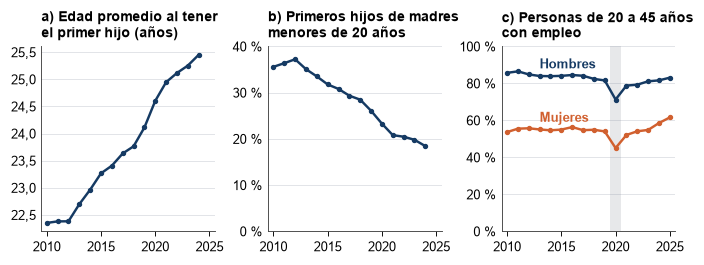

In [4]:
def figura_contexto() -> None:
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(ANCHO, 2.3))
    a.plot(vitales.index, vitales["edad_primer_hijo"], color=AZUL, marker="o", ms=2.5)
    a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: coma(v)))
    a.set_title(tr("a) Edad promedio al tener\nel primer hijo (años)"), loc="left")
    b.plot(vitales.index, vitales["menores_de_20"], color=AZUL, marker="o", ms=2.5)
    b.set_ylim(0, 40)
    b.yaxis.set_major_formatter(porcentaje)
    b.set_title(tr("b) Primeros hijos de madres\nmenores de 20 años"), loc="left")
    # Cada línea lleva su nombre al lado
    for columna, color in (("Mujeres", NARANJA), ("Hombres", AZUL)):
        c.plot(empleo_anual.index, empleo_anual[columna], color=color, marker="o", ms=2.5)
        c.annotate(tr(columna), (2013, empleo_anual.loc[2013, columna]), xytext=(0, 5),
                   textcoords="offset points", color=color, fontweight="bold", fontsize=8.5)
    c.axvspan(2019.5, 2020.5, color=GRIS, alpha=0.18, lw=0)
    c.set_ylim(0, 100)
    c.yaxis.set_major_formatter(porcentaje)
    c.set_title(tr("c) Personas de 20 a 45 años\ncon empleo"), loc="left")
    for ax in (a, b, c):
        ax.set_xticks([2010, 2015, 2020, 2025])
        ax.set_xlim(2009.5, 2025.5)
        ax.grid(axis="x", visible=False)
    guardar(fig, "contexto")


en_cada_idioma(figura_contexto)

## 2. ¿Identifica bien la encuesta a las madres primerizas?

El método ubica a cada madre en el tiempo con la edad de su hijo mayor *que vive con ella*. Si un hijo mayor vive en otro lado (con los abuelos, con el padre o ya independizado), la madre parece primeriza sin serlo. Eso se puede comprobar con las Estadísticas Vitales, que registran cuántos hijos tiene cada madre al dar a luz.

La prueba es esta. Entre las madres de la ENAHO que tienen un bebé de 0 años, ¿qué porcentaje no tiene ningún hijo mayor en el hogar? Si la encuesta clasifica bien, ese porcentaje debe parecerse al de los nacimientos que son primer hijo en las Estadísticas Vitales, para cada edad de la madre. Un bebé de 0 años en la encuesta de julio de un año nació en ese año o en el anterior, así que se comparan las encuestas de 2010 a 2024 con los nacimientos de 2009 a 2024.

In [5]:
EDADES = [19, 24, 29, 34, 39, 45]
ETIQUETAS = ["20-24", "25-29", "30-34", "35-39", "40-45"]
con_bebe = personas[personas["mujer"] & (personas["n_hijos"] > 0)
                    & (personas["edad_hijo_menor"] == 0) & (personas["anio"] <= 2024)].copy()
con_bebe["primeriza"] = (con_bebe["edad_hijo_mayor"] == 0).astype(int)
con_bebe["grupo"] = pd.cut(con_bebe["edad"], EDADES, labels=ETIQUETAS)
nac = nacimientos.assign(primero=(nacimientos["hijos_tenidos"] == 1).astype(int),
                         grupo=pd.cut(nacimientos["edad_madre"], EDADES, labels=ETIQUETAS))
grupos_enaho = con_bebe.groupby("grupo", observed=True)
grupos_vitales = nac.groupby("grupo", observed=True)
validacion = pd.DataFrame({
    "madres con un bebé (ENAHO)": grupos_enaho.size(),
    "ENAHO: sin hijo mayor en el hogar (%)":
        grupos_enaho.apply(lambda d: 100 * media(d, "primeriza"), include_groups=False),
    "nacimientos (Vitales)": grupos_vitales.size(),
    "Vitales: primer hijo (%)": grupos_vitales["primero"].mean() * 100,
})
validacion["diferencia (puntos)"] = validacion.iloc[:, 1] - validacion.iloc[:, 3]
bebes = con_bebe[con_bebe["grupo"].notna()]
total = {"madres con un bebé (ENAHO)": len(bebes),
         "ENAHO: sin hijo mayor en el hogar (%)": 100 * media(bebes, "primeriza"),
         "nacimientos (Vitales)": int(nac["grupo"].notna().sum()),
         "Vitales: primer hijo (%)": 100 * nac.loc[nac["grupo"].notna(), "primero"].mean()}
total["diferencia (puntos)"] = (total["ENAHO: sin hijo mayor en el hogar (%)"]
                                - total["Vitales: primer hijo (%)"])
validacion.loc["20-45"] = total
validacion.round(1)

,madres con un bebé (ENAHO),ENAHO: sin hijo mayor en el hogar (%),nacimientos (Vitales),Vitales: primer hijo (%),diferencia (puntos)
grupo,,,,,
20-24,1214,54.3,279052,49.8,4.5
25-29,1393,30.7,271207,32.0,-1.2
30-34,1047,24.2,201955,25.7,-1.5
35-39,612,18.3,101471,19.1,-0.7
40-45,182,15.1,24487,13.8,1.3
20-45,4448,32.7,878172,34.2,-1.5


La encuesta reproduce de cerca lo que registran las Estadísticas Vitales en cada grupo de edad. La diferencia más grande, en las madres de 20 a 24 años, es de unos pocos puntos, porque algunas madres jóvenes tienen un hijo mayor que vive con los abuelos. A partir de los 25 años no hay un exceso de «falsas primerizas», ni siquiera entre las madres de 40 a 45. Por eso el análisis usa solo los primeros diez años después del nacimiento. En ese tramo el hijo mayor casi siempre sigue en casa, y la clasificación es confiable.

## 3. El pseudo-panel

La muestra sigue a Kleven, Landais y Leite-Mariante (2025). Las madres y los padres son personas cuyo hijo mayor en el hogar tiene de 0 a 10 años y que lo tuvieron entre los 20 y los 45 años. Su *año de evento* es la edad de ese hijo, 0 el año del nacimiento, 1 el siguiente, y así hasta 10. Las personas sin hijos tienen de 15 a 44 años, no tienen hijos en el hogar y no quedaron marcadas como inciertas en el cuaderno 1.

Una madre o padre en el año 0, encuestado en el año *a* con *e* años de edad, se empareja con todas las personas sin hijos encuestadas en el año *a − n*, con *e − n* años y el mismo sexo, nivel educativo (4 grupos), estado civil (4 grupos) y zona (urbana o rural), para *n* = 1 a 5. Esas personas son su «yo» de *n* años antes del nacimiento. Si hay varias en la misma celda, cada una pesa en proporción a su factor de expansión.

Los primeros hijos antes de los 20 años quedan fuera, como en los estudios de referencia. Para ellas, los años previos al nacimiento son la adolescencia, cuando casi nadie trabaja, y no hay con qué comparar.

In [6]:
EVENTOS = list(range(-5, 11))   # años desde el nacimiento del primer hijo
DESPUES = list(range(0, 11))
# Variables de emparejamiento, como en Kleven, Landais y Leite-Mariante (2025)
CLAVES = ["mujer", "educacion", "estado_civil", "urbano"]
RESULTADOS = ["empleo", "trabajando", "participa", "horas", "ingreso_relativo", "empleo_formal",
              "empleo_informal"]

completos = (personas["educacion"] != "") & (personas["estado_civil"] != "")
padres = personas[completos & (personas["n_hijos"] > 0)
                  & personas["edad_primer_hijo"].between(20, 45)
                  & personas["edad_hijo_mayor"].between(0, 10)].copy()
padres["t"] = padres["edad_hijo_mayor"].astype(int)
sin_hijos = personas[completos & (personas["n_hijos"] == 0) & ~personas["incierto"]
                     & personas["edad"].between(15, 44)].copy()
print(f"Madres y padres en los años 0 a 10: {len(padres):,} ({int(padres['mujer'].sum()):,} madres "
      f"y {int((~padres['mujer']).sum()):,} padres)")
print(f"En el año 0 (hijo de 0 años): {int((padres['t'] == 0).sum()):,}")
print(f"Personas sin hijos de 15 a 44 años: {len(sin_hijos):,}")


def construir_pseudopanel(padres: pd.DataFrame, sin_hijos: pd.DataFrame, claves=CLAVES,
                          grupo: str | None = None, previos: int = 5) -> pd.DataFrame:
    """Une las observaciones reales (años 0 a 10) con las de antes del nacimiento (años -1 a -5),
    que aportan las personas sin hijos."""
    padres = padres.assign(grupo=padres[grupo] if grupo else "Todos")
    celda = ["anio", "edad"] + list(claves)
    en_cero = padres[padres["t"] == 0].groupby(["grupo"] + celda, as_index=False)["factor"].sum()
    en_cero = en_cero.rename(columns={"factor": "peso_padres"})
    reserva = sin_hijos.assign(peso_celda=sin_hijos.groupby(celda)["factor"].transform("sum"))
    antes = []
    for n in range(1, previos + 1):
        buscadas = en_cero.assign(anio=en_cero["anio"] - n, edad=en_cero["edad"] - n)
        pares = buscadas.merge(reserva, on=celda)
        peso = pares["peso_padres"] * pares["factor"] / pares["peso_celda"]
        antes.append(pares.assign(t=-n, peso=peso))
    antes = pd.concat(antes, ignore_index=True)
    # Si una persona sin hijos sirve a varias celdas en el mismo año de evento, se suman sus pesos
    antes = antes.groupby(["grupo", "id", "t"], as_index=False).agg(
        {**{c: "first" for c in ["hogar", "anio", "edad", "mujer"] + RESULTADOS}, "peso": "sum"})
    columnas = ["grupo", "id", "t", "hogar", "anio", "edad", "mujer", "peso"] + RESULTADOS
    despues = padres.assign(peso=padres["factor"])[columnas]
    return pd.concat([despues, antes], ignore_index=True)


def cobertura(padres: pd.DataFrame, sin_hijos: pd.DataFrame, claves=CLAVES,
              previos: int = 5) -> pd.Series:
    """Porcentaje del peso de las madres y padres en el año 0 que encontró al menos una persona
    sin hijos en cada año previo."""
    celda = ["anio", "edad"] + list(claves)
    en_cero = padres[padres["t"] == 0].groupby(celda, as_index=False)["factor"].sum()
    hay = sin_hijos[celda].drop_duplicates()
    resultado = {}
    for n in range(1, previos + 1):
        buscadas = en_cero.assign(anio=en_cero["anio"] - n, edad=en_cero["edad"] - n)
        buscadas = buscadas[buscadas["anio"] >= PRIMER_ANIO]   # antes de 2010 no hay encuesta
        encontradas = buscadas.merge(hay, on=celda)["factor"].sum()
        resultado[-n] = 100 * encontradas / buscadas["factor"].sum()
    return pd.Series(resultado, name="con pareja encontrada (%)")


panel = construir_pseudopanel(padres, sin_hijos)
print(f"Pseudo-panel: {len(panel):,} observaciones")
por_evento = panel.groupby(["t", "mujer"]).size().unstack()
por_evento = por_evento.rename(columns={True: "mujeres", False: "hombres"})
pd.concat([por_evento, cobertura(padres, sin_hijos)], axis=1).T

Madres y padres en los años 0 a 10: 41,629 (21,724 madres y 19,905 padres)
En el año 0 (hijo de 0 años): 2,860
Personas sin hijos de 15 a 44 años: 134,453


Pseudo-panel: 132,162 observaciones


,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
hombres,6478.000,7445.000,7805.000,8517.000,8726.000,1378.0,1466.0,1598.0,1719.0,1826.0,1857.0,1921.0,1989.0,2014.0,2020.0,2117.0
mujeres,9538.000,10378.000,10738.000,10658.000,10250.000,1482.0,1558.0,1721.0,1885.0,1998.0,2094.0,2062.0,2174.0,2220.0,2210.0,2320.0
con pareja encontrada (%),84.632,87.325,90.991,92.211,92.705,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Más del 90 % de las madres y padres en el año 0 encuentra personas comparables uno y dos años antes. La cobertura baja hacia el año −5 porque algunas combinaciones casi no existen cinco años antes. Por ejemplo, para quien tuvo su primer hijo a los 21 años y está en unión, haría falta una persona en unión de 16 años. Los años en que no hay encuesta (antes de 2010) no cuentan en este cálculo. En los años previos al nacimiento hay más filas que después porque cada madre o padre se compara con todas las personas sin hijos de su celda, cada una con una fracción de su peso.

La regresión se estima para mujeres y hombres por separado.

$$Y_{it} = \sum_{k \neq -2} \alpha_k \, \mathbb{1}[\text{año de evento}_{it} = k] + \sum_{e} \beta_e \, \mathbb{1}[\text{edad}_{it} = e] + \sum_{a} \gamma_a \, \mathbb{1}[\text{año}_{it} = a] + \varepsilon_{it}$$

Los $\alpha_k$ miden el cambio respecto al año −2, el anterior al embarazo. La edad y el año de la encuesta absorben lo que cambia con el ciclo de vida y con la economía. Cada $\alpha_k$ se expresa en porcentaje del nivel que se tendría sin hijos, $P_k = \alpha_k / \mathrm{E}[\tilde Y \mid k]$, donde $\tilde Y$ es la predicción sin los términos de evento.

La *penalización por maternidad* resume en un número cuánto más cae la madre que el padre en los años 0 a 10, descontando cualquier diferencia previa al nacimiento.

$$\text{Penalización} = \mathrm{E}\left[P^{h}_k - P^{m}_k \mid k \geq 0\right] - \mathrm{E}\left[P^{h}_k - P^{m}_k \mid k < 0\right]$$

Los errores estándar se agrupan por hogar y las regresiones de mujeres y hombres se estiman juntas, para que la penalización tenga en cuenta que madres y padres de un mismo hogar no son independientes.

In [7]:
def matriz(d: pd.DataFrame, base: int) -> tuple[sp.csr_matrix, list]:
    """Matriz dispersa de variables 0/1 con la constante, los años de evento (sin el año base), la
    edad y el año de la encuesta (sin la primera categoría)."""
    eventos = [("t", t) for t in EVENTOS if t != base and (d["t"] == t).any()]
    edades = [("edad", e) for e in sorted(d["edad"].unique())[1:]]
    anios = [("anio", a) for a in sorted(d["anio"].unique())[1:]]
    nombres = ["constante"] + eventos + edades + anios
    posicion = {nombre: j for j, nombre in enumerate(nombres)}
    filas, columnas = [np.arange(len(d))], [np.zeros(len(d), dtype=int)]
    for variable in ("t", "edad", "anio"):
        codigos = {v: posicion[(variable, v)] for v in d[variable].unique()
                   if (variable, v) in posicion}
        j = d[variable].map(codigos).to_numpy()
        presentes = ~np.isnan(j)
        filas.append(np.flatnonzero(presentes))
        columnas.append(j[presentes].astype(int))
    filas, columnas = np.concatenate(filas), np.concatenate(columnas)
    X = sp.csr_matrix((np.ones(len(filas)), (filas, columnas)), shape=(len(d), len(nombres)))
    return X, nombres


def estudio_de_eventos(panel: pd.DataFrame, resultado: str, base: int = -2) -> dict:
    """Una regresión por grupo y sexo, estimadas juntas, con errores agrupados por hogar."""
    bloques = []
    for (grupo, mujer), d in panel.groupby(["grupo", "mujer"], sort=True):
        X, nombres = matriz(d, base)
        bloques.append({"grupo": grupo, "sexo": "Mujeres" if mujer else "Hombres", "datos": d,
                        "X": X, "nombres": nombres})
    X = sp.block_diag([b["X"] for b in bloques], format="csr")
    datos = pd.concat([b["datos"] for b in bloques])
    y = datos[resultado].to_numpy(float)
    w = datos["peso"].to_numpy() / datos["peso"].mean()
    XtW = X.T.multiply(w).tocsr()
    A_inv = np.linalg.inv((XtW @ X).toarray())
    beta = A_inv @ (XtW @ y)
    residuo = y - X @ beta
    hogar = pd.factorize(datos["hogar"])[0]
    por_hogar = sp.csr_matrix((np.ones(len(hogar)), (hogar, np.arange(len(hogar)))))
    suma_por_hogar = por_hogar @ X.multiply((w * residuo)[:, None]).tocsr()
    g, n, k = hogar.max() + 1, len(y), X.shape[1]
    V = A_inv @ (suma_por_hogar.T @ suma_por_hogar).toarray() @ A_inv
    V = V * g / (g - 1) * (n - 1) / (n - k)

    filas, inicio = [], 0
    for b in bloques:
        coef = beta[inicio:inicio + len(b["nombres"])]
        sin_evento = np.array([0.0 if isinstance(nm, tuple) and nm[0] == "t" else c
                               for nm, c in zip(b["nombres"], coef)])
        contrafactual = b["X"] @ sin_evento
        t_obs, peso = b["datos"]["t"].to_numpy(), b["datos"]["peso"].to_numpy()
        for t in EVENTOS:
            if not (t_obs == t).any():
                continue
            j = b["nombres"].index(("t", t)) if t != base else None
            filas.append({"grupo": b["grupo"], "sexo": b["sexo"], "t": t,
                          "columna": np.nan if j is None else inicio + j,
                          "nivel_sin_hijos": np.average(contrafactual[t_obs == t],
                                                        weights=peso[t_obs == t]),
                          "efecto_nivel": 0.0 if j is None else coef[j],
                          "ee_nivel": 0.0 if j is None else np.sqrt(V[inicio + j, inicio + j]),
                          "observado": np.average(b["datos"][resultado].to_numpy()[t_obs == t],
                                                  weights=peso[t_obs == t])})
        inicio += len(b["nombres"])
    tabla = pd.DataFrame(filas).set_index(["grupo", "sexo", "t"])
    tabla["efecto"] = tabla["efecto_nivel"] / tabla["nivel_sin_hijos"]
    tabla["ee"] = tabla["ee_nivel"] / tabla["nivel_sin_hijos"]
    return {"tabla": tabla, "beta": beta, "V": V, "base": base, "resultado": resultado}


def combinar(est: dict, pesos: dict, en_porcentaje: bool = True) -> tuple[float, float]:
    """Valor y error estándar de una suma ponderada de efectos; el año base vale 0."""
    c = np.zeros(len(est["beta"]))
    for clave, peso in pesos.items():
        fila = est["tabla"].loc[clave]
        if not np.isnan(fila["columna"]):
            c[int(fila["columna"])] += peso / (fila["nivel_sin_hijos"] if en_porcentaje else 1.0)
    return float(c @ est["beta"]), float(np.sqrt(c @ est["V"] @ c))


def pesos_efecto(est, grupo, sexo, tramo=DESPUES):
    disponibles = [t for t in tramo if (grupo, sexo, t) in est["tabla"].index]
    return {(grupo, sexo, t): 1 / len(disponibles) for t in disponibles}


def efecto_promedio(est, grupo="Todos", sexo="Mujeres", tramo=DESPUES, en_porcentaje=True):
    return combinar(est, pesos_efecto(est, grupo, sexo, tramo), en_porcentaje)


def pesos_penalizacion(est, grupo, signo=1.0):
    tabla = est["tabla"]
    comunes = set(tabla.loc[(grupo, "Mujeres")].index) & set(tabla.loc[(grupo, "Hombres")].index)
    despues = [t for t in DESPUES if t in comunes]
    antes = [t for t in EVENTOS if t < 0 and t in comunes]
    pesos = {}
    for tramo, factor in ((despues, 1 / len(despues)), (antes, -1 / len(antes))):
        for t in tramo:
            pesos[(grupo, "Hombres", t)] = pesos.get((grupo, "Hombres", t), 0) + signo * factor
            pesos[(grupo, "Mujeres", t)] = pesos.get((grupo, "Mujeres", t), 0) - signo * factor
    return pesos


def penalizacion(est, grupo="Todos"):
    return combinar(est, pesos_penalizacion(est, grupo))


def diferencia_penalizacion(est, grupo_a, grupo_b):
    pesos = pesos_penalizacion(est, grupo_a)
    for clave, peso in pesos_penalizacion(est, grupo_b, signo=-1.0).items():
        pesos[clave] = pesos.get(clave, 0) + peso
    return combinar(est, pesos)


def prueba_tendencias_previas(est, grupo="Todos", sexo="Mujeres"):
    """Prueba de Wald de que los efectos de los años previos (salvo el base) son todos cero."""
    tabla = est["tabla"].loc[(grupo, sexo)]
    j = [int(c) for t, c in tabla["columna"].items() if t < 0 and not np.isnan(c)]
    b, V = est["beta"][j], est["V"][np.ix_(j, j)]
    estadistico = float(b @ np.linalg.solve(V, b))
    return estadistico, float(chi2.sf(estadistico, len(j)))


def resumen(est, grupo="Todos") -> dict:
    pen, pen_ee = penalizacion(est, grupo)
    muj, muj_ee = efecto_promedio(est, grupo, "Mujeres")
    hom, hom_ee = efecto_promedio(est, grupo, "Hombres")
    return {"penalización": pen, "ee penalización": pen_ee, "efecto en las madres": muj,
            "ee madres": muj_ee, "efecto en los padres": hom, "ee padres": hom_ee}

## 4. Resultado principal en el empleo

In [8]:
empleo = estudio_de_eventos(panel, "empleo")
columnas = ["efecto", "ee", "efecto_nivel", "nivel_sin_hijos", "observado"]
tabla_empleo = empleo["tabla"].loc["Todos"][columnas].unstack("sexo")
(100 * tabla_empleo).round(1)

efecto              ee         efecto_nivel         nivel_sin_hijos  \
sexo Hombres Mujeres Hombres Mujeres      Hombres Mujeres         Hombres   
t                                                                           
-5       2.5     3.5     1.2     3.1          2.0     1.5            81.5   
-4       2.3     1.2     1.0     2.8          1.9     0.5            83.8   
-3       0.7     1.6     1.0     2.5          0.6     0.8            85.7   
-2       0.0     0.0     0.0     0.0          0.0     0.0            87.8   
-1      -0.2    -0.1     0.9     2.1         -0.2    -0.1            89.2   
 0       1.1   -29.8     1.2     2.9          1.0   -18.0            90.3   
 1       1.1   -29.1     1.1     2.8          1.0   -18.7            91.6   
 2       2.3   -24.9     1.0     2.6          2.1   -16.7            92.3   
 3       1.3   -29.4     1.0     2.4          1.2   -20.3            92.7   
 4      -0.1   -26.7     1.0     2.4         -0.1   -18.9            93.1   
 5       1.0   -25.2     1.0     2.3          1.0   -18.2            93.3   
 6      -0.7   -28.6     1.0     2.3         -0.6   -21.2            93.4   
 7       1.6   -28.7     0.9     2.2          1.5   -21.7            93.6   
 8       0.2   -29.5     1.0     2.2          0.2   -22.7            93.8   
 9      -0.3   -30.6     1.0     2.2         -0.2   -24.0            93.9   
 10     -0.0   -32.0     1.0     2.1         -0.0   -25.3            93.8   

             observado          
sexo Mujeres   Hombres Mujeres  
t                               
-5      41.9      83.6    43.3  
-4      44.7      85.7    45.2  
-3      48.2      86.3    49.0  
-2      52.6      87.8    52.6  
-1      56.4      89.0    56.3  
 0      60.4      91.4    42.5  
 1      64.2      92.6    45.5  
 2      67.0      94.4    50.3  
 3      69.1      93.9    48.8  
 4      70.9      93.1    51.9  
 5      72.3      94.3    54.1  
 6      74.0      92.8    52.8  
 7      75.7      95.1    54.0  
 8      77.0      94.0    54.3  
 9      78.3      93.6    54.3  
 10     79.2      93.8    53.9

In [9]:
principal = resumen(empleo)
nivel_madres, nivel_madres_ee = efecto_promedio(empleo, en_porcentaje=False)
madres_empleo = empleo["tabla"].loc[("Todos", "Mujeres")]
contrafactual_madres = madres_empleo.loc[DESPUES, "nivel_sin_hijos"].mean()
salto_padres = combinar(empleo, {("Todos", "Hombres", 0): 1, ("Todos", "Hombres", -1): -1})
previas = {sexo: prueba_tendencias_previas(empleo, sexo=sexo) for sexo in ("Mujeres", "Hombres")}
caida_t0, caida_t0_ee = combinar(empleo, {("Todos", "Mujeres", 0): 1})
final, final_ee = efecto_promedio(empleo, tramo=range(5, 11))

print(f"Penalización por maternidad en el empleo: {100 * principal['penalización']:.1f} % (EE "
      f"{100 * principal['ee penalización']:.1f})")
print(f"Efecto en las madres, años 0-10: {100 * principal['efecto en las madres']:.1f} % (EE "
      f"{100 * principal['ee madres']:.1f}); en puntos: {100 * nivel_madres:.1f} (EE "
      f"{100 * nivel_madres_ee:.1f}), sobre un empleo sin hijos de "
      f"{100 * contrafactual_madres:.1f} %")
print(f"Efecto en los padres, años 0-10: {100 * principal['efecto en los padres']:.1f} % (EE "
      f"{100 * principal['ee padres']:.1f})")
print(f"Madres: año 0 {100 * caida_t0:.1f} % (EE {100 * caida_t0_ee:.1f}); años 5-10 "
      f"{100 * final:.1f} % (EE {100 * final_ee:.1f})")
print(f"Salto de los padres entre el año -1 y el 0: {100 * salto_padres[0]:.1f} % (EE "
      f"{100 * salto_padres[1]:.1f})")
for sexo, (estadistico, p) in previas.items():
    print(f"Tendencias previas, {sexo.lower()}: chi2 = {estadistico:.2f}, p = {p:.3f}")

Penalización por maternidad en el empleo: 29.5 % (EE 1.6)
Efecto en las madres, años 0-10: -28.6 % (EE 1.6); en puntos: -20.5 (EE 1.2), sobre un empleo sin hijos de 71.6 %
Efecto en los padres, años 0-10: 0.7 % (EE 0.8)
Madres: año 0 -29.8 % (EE 2.9); años 5-10 -29.1 % (EE 1.6)
Salto de los padres entre el año -1 y el 0: 1.3 % (EE 1.2)
Tendencias previas, mujeres: chi2 = 1.73, p = 0.785
Tendencias previas, hombres: chi2 = 9.44, p = 0.051


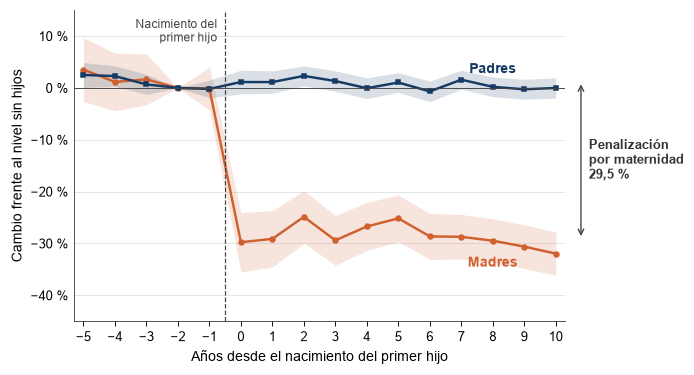

In [10]:
def grafico_eventos(ax, est, grupo="Todos", titulo="", eje_y="Cambio frente al nivel sin hijos"):
    """Efecto de cada año para madres y padres. La franja sombreada es el intervalo de confianza
    al 95 %."""
    for sexo, color, marcador in (("Mujeres", NARANJA, "o"), ("Hombres", AZUL, "s")):
        t = est["tabla"].loc[(grupo, sexo)]
        ax.fill_between(t.index, 100 * (t["efecto"] - 1.96 * t["ee"]),
                        100 * (t["efecto"] + 1.96 * t["ee"]), color=color, alpha=0.16, lw=0)
        ax.plot(t.index, 100 * t["efecto"], color=color, marker=marcador, ms=3.2)
    ax.axvline(-0.5, color="#444444", lw=0.8, ls="--")
    ax.axhline(0, color="#444444", lw=0.6)
    ax.set_xticks(EVENTOS)
    ax.set_xlim(-5.3, 10.3)
    ax.set_xlabel(tr("Años desde el nacimiento del primer hijo"))
    ax.set_ylabel(tr(eje_y) if eje_y else "")
    ax.yaxis.set_major_formatter(porcentaje)
    ax.grid(axis="x", visible=False)
    if titulo:
        ax.set_title(titulo, loc="left")


def rotular(ax, est, anio=8):
    """Escribe «Padres» y «Madres» junto a su línea, en lugar de una leyenda aparte."""
    t = est["tabla"].loc["Todos"]
    ax.annotate(tr("Padres"), (anio, 100 * t.loc[("Hombres", anio), "efecto"]), xytext=(0, 9),
                textcoords="offset points", ha="center", color=AZUL, fontweight="bold")
    ax.annotate(tr("Madres"), (anio, 100 * t.loc[("Mujeres", anio), "efecto"]), xytext=(0, -17),
                textcoords="offset points", ha="center", color=NARANJA, fontweight="bold")


def figura_evento() -> None:
    fig, ax = plt.subplots(figsize=(ANCHO, 3.3))
    grafico_eventos(ax, empleo)
    rotular(ax, empleo)
    ax.set_ylim(-45, 15)
    ax.annotate(tr("Nacimiento del\nprimer hijo"), (-0.5, 13.5), xytext=(-5, 0),
                textcoords="offset points", ha="right", va="top", fontsize=8, color="#444444")
    # La penalización es la distancia entre las líneas después del nacimiento, menos la de antes
    medio_madres = 100 * principal["efecto en las madres"]
    medio_padres = 100 * principal["efecto en los padres"]
    ax.annotate("", xy=(10.8, medio_madres), xytext=(10.8, medio_padres), annotation_clip=False,
                arrowprops={"arrowstyle": "<->", "color": "#444444", "lw": 0.9, "shrinkA": 0,
                            "shrinkB": 0})
    ax.text(11.05, (medio_madres + medio_padres) / 2,
            tr("Penalización\npor maternidad\n{valor}").format(
                valor=por_ciento(100 * principal["penalización"])),
            va="center", fontsize=8.5, fontweight="bold", color="#333333", clip_on=False)
    guardar(fig, "evento_empleo")


en_cada_idioma(figura_evento)

Antes del nacimiento, madres y padres siguen la misma trayectoria. Los efectos de los años −5 a −1 son de pocos puntos y la prueba conjunta no los distingue de cero al 5 %, aunque en los padres queda en el límite por diferencias de unos 2 puntos en los años −5 y −4. Con el primer hijo, el empleo de las madres cae de golpe y no se recupera en los diez años siguientes. El de los padres no cambia. Esa es la penalización por maternidad.

En niveles, el empleo que las madres tendrían sin hijos en esos años ronda el 72 %; con el hijo es unos 20 puntos menor. La caída no se debe a la licencia de maternidad, porque quienes están en licencia cuentan como ocupadas, y excluirlas da el mismo resultado (sección 8).

## 5. ¿Funciona el emparejamiento? La prueba de los hombres

Los estudios con paneles reales muestran que tener un hijo no cambia el empleo de los hombres. Por eso, si el pseudo-panel mostrara un salto en el empleo de los padres al nacer el hijo, sería una señal de que las personas sin hijos con que se les compara no son comparables (Kleven, 2022). La tabla agrega las variables de emparejamiento de una en una.

In [11]:
especificaciones = {
    "Solo año, edad y sexo": ["mujer"],
    "+ educación": ["mujer", "educacion"],
    "+ estado civil": ["mujer", "educacion", "estado_civil"],
    "+ zona urbana o rural (base)": CLAVES,
}
filas = {}
for nombre, claves in especificaciones.items():
    est = estudio_de_eventos(construir_pseudopanel(padres, sin_hijos, claves=claves), "empleo")
    salto = combinar(est, {("Todos", "Hombres", 0): 1, ("Todos", "Hombres", -1): -1})
    filas[nombre] = {**resumen(est), "salto de los padres en el año 0": salto[0],
                     "ee salto": salto[1]}
emparejamiento = pd.DataFrame(filas).T
(100 * emparejamiento).round(1)

,penalización,ee penalización,efecto en las madres,ee madres,efecto en los padres,ee padres,salto de los padres en el año 0,ee salto
"Solo año, edad y sexo",43.7,1.0,-29.2,0.9,14.7,0.5,17.4,1.1
+ educación,42.2,1.1,-29.9,1.0,12.9,0.6,14.3,1.1
+ estado civil,29.3,1.4,-28.9,1.5,0.3,0.7,1.1,1.1
+ zona urbana o rural (base),29.5,1.6,-28.6,1.6,0.7,0.8,1.3,1.2


Si solo se empareja por edad y sexo, el empleo de los padres «salta» más de 15 % al nacer el hijo. No es un efecto del hijo. Los hombres que tienen hijos ya trabajaban más antes, porque suelen estar casados o en unión, mientras que muchos hombres sin hijos son solteros que estudian o viven con sus padres. Al emparejar también por estado civil, el salto desaparece. El efecto en las madres casi no cambia entre especificaciones; lo que cambia es el punto de comparación de los hombres. Por eso la especificación base usa todas las variables, igual que el Atlas.

## 6. Horas, ingresos y formalidad

El mismo cálculo, con otros resultados. Las horas y el ingreso valen cero para quien no trabaja, así que combinan el efecto de dejar de trabajar con el de trabajar menos o ganar menos. El empleo formal (con cotización a la CCSS por el propio trabajo) y el informal suman el empleo total.

In [12]:
NOMBRES = {"empleo": "Empleo", "participa": "Participación laboral",
           "trabajando": "Empleo sin ausentes temporales", "horas": "Horas de trabajo por semana",
           "ingreso_relativo": "Ingreso laboral", "empleo_formal": "Empleo formal",
           "empleo_informal": "Empleo informal"}
estimaciones = {"empleo": empleo}
for r in ["participa", "trabajando", "horas", "ingreso_relativo", "empleo_formal",
          "empleo_informal"]:
    estimaciones[r] = estudio_de_eventos(panel, r)
filas = {}
for r, est in estimaciones.items():
    nivel, nivel_ee = efecto_promedio(est, en_porcentaje=False)
    sin_hijos_nivel = est["tabla"].loc[("Todos", "Mujeres")].loc[DESPUES, "nivel_sin_hijos"].mean()
    filas[NOMBRES[r]] = {**resumen(est), "madres: cambio en el nivel": nivel, "ee nivel": nivel_ee,
                         "madres: nivel sin hijos": sin_hijos_nivel}
margenes = pd.DataFrame(filas).T
margenes.round(3)

,penalización,ee penalización,efecto en las madres,ee madres,efecto en los padres,ee padres,madres: cambio en el nivel,ee nivel,madres: nivel sin hijos
Empleo,0.295,0.016,-0.286,0.016,0.007,0.008,-0.205,0.012,0.716
Participación laboral,0.295,0.012,-0.292,0.014,0.015,0.005,-0.234,0.011,0.803
Empleo sin ausentes temporales,0.294,0.017,-0.297,0.018,0.004,0.009,-0.196,0.012,0.665
Horas de trabajo por semana,0.400,0.039,-0.347,0.023,0.010,0.026,-10.817,0.697,30.875
Ingreso laboral,0.260,0.029,-0.386,0.023,-0.107,0.021,-0.345,0.020,0.869
Empleo formal,0.373,0.022,-0.384,0.019,-0.016,0.015,-0.234,0.012,0.603
Empleo informal,-0.161,0.078,0.277,0.070,0.125,0.068,0.029,0.008,0.114


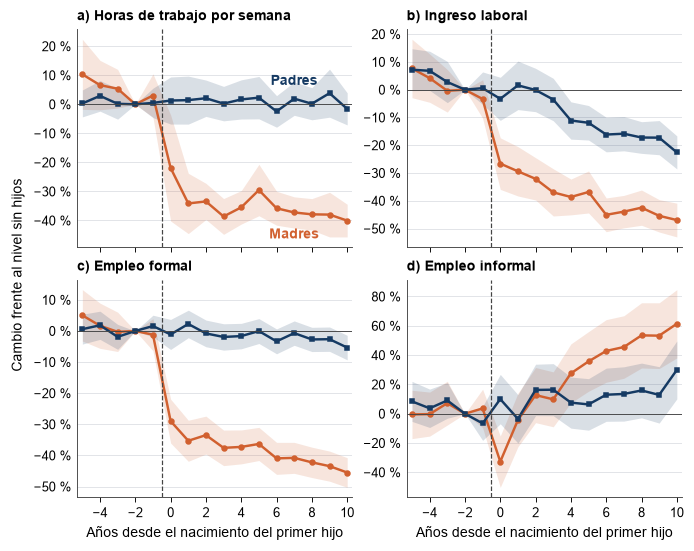

In [13]:
def figura_margenes() -> None:
    fig, ejes = plt.subplots(2, 2, figsize=(ANCHO, 4.9), sharex=True)
    paneles = ["horas", "ingreso_relativo", "empleo_formal", "empleo_informal"]
    for ax, r, letra in zip(ejes.flat, paneles, "abcd"):
        grafico_eventos(ax, estimaciones[r], titulo=f"{letra}) {tr(NOMBRES[r])}", eje_y="")
        ax.set_xticks(range(-4, 11, 2))
        if letra in "ab":
            ax.set_xlabel("")
    rotular(ejes[0, 0], estimaciones["horas"], anio=7)
    fig.supylabel(tr("Cambio frente al nivel sin hijos"), fontsize=9)
    guardar(fig, "margenes")


en_cada_idioma(figura_margenes)

In [14]:
# El cambio en puntos del empleo formal más el del informal es el del empleo total, año por año
puntos = pd.DataFrame({r: estimaciones[r]["tabla"].loc[("Todos", "Mujeres"), "efecto_nivel"]
                       for r in ["empleo", "empleo_formal", "empleo_informal"]})
assert np.allclose(puntos["empleo_formal"] + puntos["empleo_informal"], puntos["empleo"], atol=1e-8)
(100 * puntos.loc[DESPUES]).round(1).T

t,0,1,2,3,4,5,6,7,8,9,10
empleo,-18.0,-18.7,-16.7,-20.3,-18.9,-18.2,-21.2,-21.7,-22.7,-24.0,-25.3
empleo_formal,-13.8,-18.1,-18.2,-21.5,-22.1,-22.2,-25.9,-26.6,-28.2,-29.5,-31.5
empleo_informal,-4.2,-0.5,1.6,1.2,3.2,4.0,4.7,4.8,5.5,5.5,6.2


Las horas caen más que el empleo, porque muchas madres que siguen trabajando lo hacen menos horas. El ingreso laboral cae todavía más. El cambio más llamativo es el tipo de trabajo. El empleo formal de las madres cae año tras año, mientras el informal, después de una caída inicial, crece hasta superar el nivel que tendría sin hijos. Muchas madres que vuelven a trabajar lo hacen sin seguro social, en empleos más flexibles pero más precarios, como encontraron Berniell y coautores (2021, 2023) en otros países de la región.

Con el ingreso conviene una advertencia. El de los padres también se aleja poco a poco de su contrafactual en los años 4 a 10, algo que no ocurre con su empleo ni con sus horas. Es probable que el contrafactual de ingresos, construido con personas sin hijos más jóvenes, no capte bien cómo crecen los salarios con la experiencia. Por eso el informe usa el efecto en las madres y no la penalización para hablar de ingresos, y lo presenta como una aproximación.

## 7. ¿Es menor la penalización para las que postergan la maternidad?

La pregunta original de este proyecto. Se estima la penalización por separado según la edad al primer hijo, la educación, la zona y el período. Cada grupo se compara con personas sin hijos de su propio perfil, así que cada penalización está medida contra su propio punto de partida (Kleven, 2022, la llama especificación *apilada*).

In [15]:
padres["edad_primer_hijo_grupo"] = pd.cut(padres["edad_primer_hijo"], [19, 24, 29, 34, 45],
                                          labels=["20-24", "25-29", "30-34", "35-45"]).astype(str)
padres["educacion_2"] = np.where(padres["educacion"] == "Superior", "Superior",
                                 "Secundaria o menos")
edad_al_primero = np.where(padres["edad_primer_hijo"] < 30, "20-29", "30-45")
padres["educacion_y_edad"] = padres["educacion_2"] + ", primer hijo a los " + edad_al_primero
padres["zona"] = np.where(padres["urbano"] == 1, "Urbana", "Rural")
padres["periodo"] = pd.cut(padres["anio"], [2009, 2014, 2019, 2025],
                           labels=["2010-2014", "2015-2019", "2020-2025"]).astype(str)

cortes = {"Edad al primer hijo": "edad_primer_hijo_grupo", "Educación": "educacion_2",
          "Educación y edad al primer hijo": "educacion_y_edad", "Zona": "zona",
          "Período": "periodo"}
por_grupo, estimaciones_grupo = [], {}
for corte, variable in cortes.items():
    est = estudio_de_eventos(construir_pseudopanel(padres, sin_hijos, grupo=variable), "empleo")
    estimaciones_grupo[corte] = est
    for grupo in sorted(padres[variable].unique()):
        por_grupo.append({"corte": corte, "grupo": grupo,
                          "madres": int((padres[variable].eq(grupo) & padres["mujer"]).sum()),
                          **resumen(est, grupo)})
por_grupo = pd.DataFrame(por_grupo).set_index(["corte", "grupo"])
(100 * por_grupo.drop(columns="madres")).round(1).join(por_grupo["madres"])

penalización  \
corte                           grupo                                                       
Edad al primer hijo             20-24                                                20.4   
                                25-29                                                36.5   
                                30-34                                                23.3   
                                35-45                                                15.5   
Educación                       Secundaria o menos                                   30.2   
                                Superior                                             13.2   
Educación y edad al primer hijo Secundaria o menos, primer hijo a los 20-29          26.4   
                                Secundaria o menos, primer hijo a los 30-45          25.4   
                                Superior, primer hijo a los 20-29                    12.5   
                                Superior, primer hijo a los 30-45                    15.3   
Zona                            Rural                                                39.5   
                                Urbana                                               25.6   
Período                         2010-2014                                            29.0   
                                2015-2019                                            32.5   
                                2020-2025                                            31.0   

                                                                             ee penalización  \
corte                           grupo                                                          
Edad al primer hijo             20-24                                                    8.1   
                                25-29                                                    5.4   
                                30-34                                                    6.4   
                                35-45                                                    6.8   
Educación                       Secundaria o menos                                       2.6   
                                Superior                                                 1.9   
Educación y edad al primer hijo Secundaria o menos, primer hijo a los 20-29              4.2   
                                Secundaria o menos, primer hijo a los 30-45              5.8   
                                Superior, primer hijo a los 20-29                        4.9   
                                Superior, primer hijo a los 30-45                        2.8   
Zona                            Rural                                                    3.4   
                                Urbana                                                   1.8   
Período                         2010-2014                                                4.0   
                                2015-2019                                                3.2   
                                2020-2025                                                3.1   

                                                                             efecto en las madres  \
corte                           grupo                                                               
Edad al primer hijo             20-24                                                       -29.1   
                                25-29                                                       -33.8   
                                30-34                                                       -21.1   
                                35-45                                                       -11.0   
Educación                       Secundaria o menos                                          -29.6   
                                Superior                                                    -12.0   
Educación y edad al primer hijo Secundaria o menos, pr

In [16]:
# ¿Son estadísticamente distintas? Diferencias de penalización entre grupos, con su error estándar
pruebas = {
    "Primer hijo a los 30-34 menos 25-29": ("Edad al primer hijo", "30-34", "25-29"),
    "Primer hijo a los 35-45 menos 25-29": ("Edad al primer hijo", "35-45", "25-29"),
    "Superior menos secundaria o menos": ("Educación", "Superior", "Secundaria o menos"),
    "Secundaria o menos: 30-45 menos 20-29": ("Educación y edad al primer hijo",
                                              "Secundaria o menos, primer hijo a los 30-45",
                                              "Secundaria o menos, primer hijo a los 20-29"),
    "Superior: 30-45 menos 20-29": ("Educación y edad al primer hijo",
                                    "Superior, primer hijo a los 30-45",
                                    "Superior, primer hijo a los 20-29"),
    "Rural menos urbana": ("Zona", "Rural", "Urbana"),
    "2020-2025 menos 2010-2014": ("Período", "2020-2025", "2010-2014"),
}
diferencias = {}
for nombre, (corte, a, b) in pruebas.items():
    valor, ee = diferencia_penalizacion(estimaciones_grupo[corte], a, b)
    diferencias[nombre] = {"diferencia (puntos de penalización)": 100 * valor, "ee": 100 * ee,
                           "z": valor / ee}
diferencias = pd.DataFrame(diferencias).T
diferencias.round(2)

,diferencia (puntos de penalización),ee,z
Primer hijo a los 30-34 menos 25-29,-13.18,8.43,-1.56
Primer hijo a los 35-45 menos 25-29,-20.93,8.73,-2.40
Superior menos secundaria o menos,-17.00,3.21,-5.29
Secundaria o menos: 30-45 menos 20-29,-1.03,7.13,-0.14
Superior: 30-45 menos 20-29,2.87,5.65,0.51
Rural menos urbana,13.96,3.88,3.60
2020-2025 menos 2010-2014,1.97,5.04,0.39


In [17]:
# ¿Quiénes postergan? Madres con educación superior, según la edad a la que tuvieron su primer hijo
madres = padres[padres["mujer"]]


def con_superior(d: pd.DataFrame) -> float:
    return 100 * np.average(d["educacion"] == "Superior", weights=d["factor"])


edad_al_primero = np.where(madres["edad_primer_hijo"] < 30, "20-29", "30-45")
superior_por_edad = madres.groupby(edad_al_primero).apply(con_superior, include_groups=False)
superior_por_edad = superior_por_edad.rename("con educación superior (%)")
superior_por_edad.round(1)

20-29    26.9
30-45    47.9
Name: con educación superior (%), dtype: float64

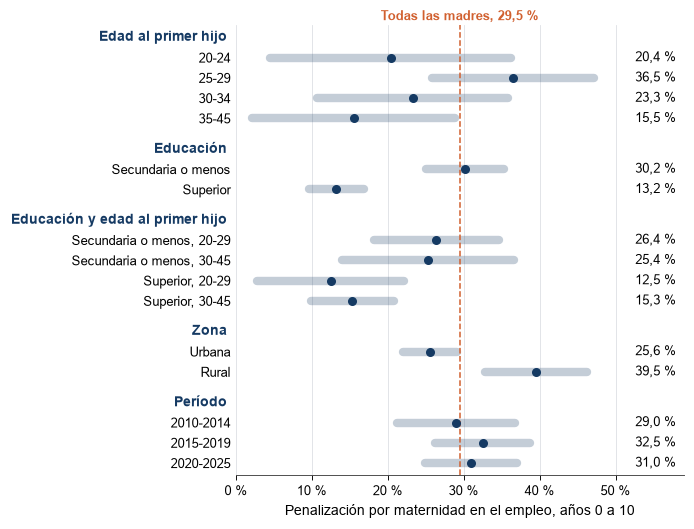

In [18]:
EDUCACION_Y_EDAD = [f"{e}, primer hijo a los {a}" for e in ("Secundaria o menos", "Superior")
                    for a in ("20-29", "30-45")]
GRUPOS_EN_ORDEN = {
    "Edad al primer hijo": ["20-24", "25-29", "30-34", "35-45"],
    "Educación": ["Secundaria o menos", "Superior"],
    "Educación y edad al primer hijo": EDUCACION_Y_EDAD,
    "Zona": ["Urbana", "Rural"],
    "Período": ["2010-2014", "2015-2019", "2020-2025"],
}
orden = [(corte, g) for corte, grupos in GRUPOS_EN_ORDEN.items() for g in grupos]
etiquetas = {g: g.replace("primer hijo a los ", "") for g in EDUCACION_Y_EDAD}


def figura_heterogeneidad() -> None:
    fig, ax = plt.subplots(figsize=(ANCHO, 4.7))
    y, posiciones, nombres_y = 0.0, [], []
    for i, (corte, grupo) in enumerate(orden):
        if i == 0 or corte != orden[i - 1][0]:   # nombre del bloque, en una fila propia
            y += 0.5 if i else 0
            ax.text(-0.02, -y, tr(corte), transform=ax.get_yaxis_transform(), ha="right",
                    va="center", fontweight="bold", color=AZUL)
            y += 1
        fila = por_grupo.loc[(corte, grupo)]
        centro, margen = 100 * fila["penalización"], 196 * fila["ee penalización"]
        # Intervalo al 95 %
        ax.plot([centro - margen, centro + margen], [-y, -y], color=AZUL, alpha=0.25, lw=5.5,
                solid_capstyle="round")
        ax.scatter([centro], [-y], s=24, color=AZUL, zorder=3)
        ax.text(58, -y, por_ciento(centro), va="center", ha="right", fontsize=8.5)
        posiciones.append(-y)
        nombres_y.append(tr(etiquetas.get(grupo, grupo)))
        y += 1
    total = 100 * principal["penalización"]
    ax.axvline(total, color=NARANJA, ls="--", lw=1)
    ax.text(total, 1.005, tr("Todas las madres, {valor}").format(valor=por_ciento(total)),
            color=NARANJA, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            fontsize=8.5, fontweight="bold")
    ax.set_yticks(posiciones, nombres_y)
    ax.set_ylim(-(y - 0.4), 0.6)
    ax.set_xlim(0, 59)
    ax.set_xticks(range(0, 51, 10))
    ax.xaxis.set_major_formatter(porcentaje)
    ax.set_xlabel(tr("Penalización por maternidad en el empleo, años 0 a 10"))
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    guardar(fig, "heterogeneidad")


en_cada_idioma(figura_heterogeneidad)

En el agregado, las mujeres que tuvieron su primer hijo a los 30 o más tienen una penalización menor que las que lo tuvieron entre los 25 y los 29 (la de 20 a 24 años es poco precisa). Pero esa diferencia coincide con otra más fuerte, la de la educación. Las madres con educación superior tienen una penalización de menos de la mitad que las de secundaria o menos, y son también las que más postergan. Casi la mitad de las que tuvieron su primer hijo a los 30 o más tienen educación superior, frente a una de cada cuatro de las que lo tuvieron antes. Dentro de cada nivel educativo, la penalización es prácticamente la misma para las que tuvieron su primer hijo antes o después de los 30. Postergar no aparece asociado con una penalización menor; tener más educación sí. La penalización es mayor en la zona rural y no cambia entre 2010 y 2025.

Estas comparaciones son descriptivas. El momento de la maternidad no se asigna al azar, y quien posterga puede diferir en cosas que la encuesta no mide. Separar el efecto causal de postergar requeriría experimentos naturales, como abortos espontáneos o tratamientos de fertilidad (Miller, 2011; Lundborg, Plug y Rasmussen, 2017), que la ENAHO no permite observar.

## 8. Solidez

Cada fila cambia una decisión del cálculo y vuelve a estimar la penalización en el empleo.

In [19]:
JEFATURA = ["jefatura", "cónyuge"]
DISENO_MP = "Diseño de Marchionni y Pedrazzi: jefaturas y cónyuges, sin emparejar por estado civil"


def sin_ultima_encuesta(d):
    return d[d["anio"] <= 2024]


def sin_pandemia(d):
    return d[~d["anio"].isin([2020, 2021])]


def solo_jefaturas(d):
    return d[d["parentesco"].isin(JEFATURA)]


con_inciertas = personas[completos & (personas["n_hijos"] == 0) & personas["edad"].between(15, 44)]
variantes = {
    "Base": dict(),
    "Emparejar también por región de planificación": dict(claves=CLAVES + ["region"]),
    "Año base -1 en lugar de -2": dict(base=-1),
    "Primer hijo entre los 20 y los 40 años": dict(padres=padres[padres["edad_primer_hijo"] <= 40]),
    "Empleo sin ausentes temporales (licencias, vacaciones)": dict(resultado="trabajando"),
    "Participación laboral en lugar de empleo": dict(resultado="participa"),
    "Solo jefaturas y cónyuges": dict(padres=solo_jefaturas(padres),
                                      sin_hijos=solo_jefaturas(sin_hijos)),
    "Personas inciertas tratadas como sin hijos": dict(sin_hijos=con_inciertas),
    "Sin factores de expansión": dict(padres=padres.assign(factor=1.0),
                                      sin_hijos=sin_hijos.assign(factor=1.0)),
    f"Sin la encuesta de {ULTIMO_ANIO}": dict(padres=sin_ultima_encuesta(padres),
                                              sin_hijos=sin_ultima_encuesta(sin_hijos)),
    "Sin 2020 y 2021 (pandemia)": dict(padres=sin_pandemia(padres),
                                       sin_hijos=sin_pandemia(sin_hijos)),
    DISENO_MP: dict(padres=solo_jefaturas(padres), sin_hijos=solo_jefaturas(sin_hijos),
                    claves=["mujer", "educacion", "urbano"]),
}
filas = {}
for nombre, v in variantes.items():
    pnl = construir_pseudopanel(v.get("padres", padres), v.get("sin_hijos", sin_hijos),
                                claves=v.get("claves", CLAVES))
    est = estudio_de_eventos(pnl, v.get("resultado", "empleo"), base=v.get("base", -2))
    salto = combinar(est, {("Todos", "Hombres", 0): 1, ("Todos", "Hombres", -1): -1})
    filas[nombre] = {**resumen(est), "salto de los padres en el año 0": salto[0]}
solidez = pd.DataFrame(filas).T
(100 * solidez).round(1)

,penalización,ee penalización,efecto en las madres,ee madres,efecto en los padres,ee padres,salto de los padres en el año 0
Base,29.5,1.6,-28.6,1.6,0.7,0.8,1.3
Emparejar también por región de planificación,33.9,1.9,-31.3,2.0,0.3,1.0,1.5
Año base -1 en lugar de -2,29.5,1.6,-28.5,1.6,0.9,0.7,1.3
Primer hijo entre los 20 y los 40 años,29.7,1.6,-29.0,1.6,0.7,0.8,1.3
"Empleo sin ausentes temporales (licencias, vacaciones)",29.4,1.7,-29.7,1.8,0.4,0.9,0.1
Participación laboral en lugar de empleo,29.5,1.2,-29.2,1.4,1.5,0.5,1.8
Solo jefaturas y cónyuges,33.4,1.8,-32.6,2.1,1.4,0.9,1.6
Personas inciertas tratadas como sin hijos,29.3,1.6,-27.4,1.6,0.8,0.7,2.0
Sin factores de expansión,32.6,1.5,-30.9,1.5,0.8,0.7,1.1
Sin la encuesta de 2025,29.5,1.7,-28.3,1.7,0.7,0.8,1.0


La penalización va de 29 % a 36 % en todas las variantes, y el efecto en los padres nunca pasa de 2 %. Sube un poco cuando la comparación es más estrecha o más selecta, es decir, al emparejar también por región, al usar solo jefaturas y cónyuges (que deja fuera a las madres jóvenes que viven con sus padres y compara contra personas sin hijos que ya formaron su propio hogar) y con el diseño de Marchionni y Pedrazzi (2025). Excluir 2025, cuya cifra de empleo femenino conviene leer con cautela, no cambia nada.

### Errores estándar por bootstrap

Los errores estándar de arriba tratan como fijos los niveles sin hijos que sirven para expresar los efectos en porcentaje, y no incluyen la incertidumbre del emparejamiento. Un *bootstrap* por hogares sí la incluye. Se sortean hogares con reemplazo dentro de cada año, se rehace todo (pseudo-panel, regresiones y penalización) y se repite 300 veces. Tarda unos tres minutos.

In [20]:
REPETICIONES = 300
rng = np.random.default_rng(2025)
base_boot = personas[completos].sort_values(["anio", "hogar"]).reset_index(drop=True)
codigo_hogar = pd.factorize(base_boot["hogar"])[0]   # hogares contiguos y numerados en orden
inicio_hogar = np.searchsorted(codigo_hogar, np.arange(codigo_hogar.max() + 1))
largo_hogar = np.bincount(codigo_hogar)
anio_hogar = base_boot.groupby(codigo_hogar)["anio"].first().to_numpy()


def muestra_bootstrap() -> pd.DataFrame:
    """Sortea hogares con reemplazo dentro de cada año. Cada copia de un hogar cuenta como un hogar
    distinto."""
    elegidos = np.concatenate([rng.choice(np.flatnonzero(anio_hogar == a),
                                          size=int((anio_hogar == a).sum()), replace=True)
                               for a in np.unique(anio_hogar)])
    largo = largo_hogar[elegidos]
    desplazamiento = inicio_hogar[elegidos] - np.concatenate([[0], np.cumsum(largo)[:-1]])
    filas = np.repeat(desplazamiento, largo) + np.arange(largo.sum())
    d = base_boot.iloc[filas].copy()
    d["hogar"] = np.repeat(np.arange(len(elegidos)), largo)
    d["id"] = np.arange(len(d))
    return d


def penalizacion_muestra(d: pd.DataFrame) -> dict:
    p = d[(d["n_hijos"] > 0) & d["edad_primer_hijo"].between(20, 45)
          & d["edad_hijo_mayor"].between(0, 10)].copy()
    p["t"] = p["edad_hijo_mayor"].astype(int)
    s = d[(d["n_hijos"] == 0) & ~d["incierto"] & d["edad"].between(15, 44)]
    return resumen(estudio_de_eventos(construir_pseudopanel(p, s), "empleo"))


bootstrap = pd.DataFrame([penalizacion_muestra(muestra_bootstrap()) for _ in range(REPETICIONES)])
MEDIDAS = ("penalización", "efecto en las madres", "efecto en los padres")
comparacion_ee = pd.DataFrame({
    "estimación": [principal[k] for k in MEDIDAS],
    "ee agrupado": [principal[k] for k in ("ee penalización", "ee madres", "ee padres")],
    "ee bootstrap": [bootstrap[k].std() for k in MEDIDAS],
    "IC 95 % inferior": [bootstrap[k].quantile(0.025) for k in MEDIDAS],
    "IC 95 % superior": [bootstrap[k].quantile(0.975) for k in MEDIDAS],
}, index=["Penalización", "Efecto en las madres", "Efecto en los padres"])
ee_penalizacion = comparacion_ee.loc["Penalización"]
razon_ee = ee_penalizacion["ee bootstrap"] / ee_penalizacion["ee agrupado"]
print(f"El error estándar por bootstrap de la penalización es {razon_ee:.2f} veces el agrupado")
(100 * comparacion_ee).round(2)

El error estándar por bootstrap de la penalización es 1.17 veces el agrupado


,estimación,ee agrupado,ee bootstrap,IC 95 % inferior,IC 95 % superior
Penalización,29.48,1.58,1.84,26.06,33.15
Efecto en las madres,-28.58,1.62,1.54,-31.53,-25.68
Efecto en los padres,0.71,0.76,1.10,-1.08,3.01


In [21]:
# ¿Cambian las conclusiones por grupo si todos los errores estándar fueran así de mayores?
diferencias.assign(**{"z con errores del bootstrap": diferencias["z"] / razon_ee}).round(2)

,diferencia (puntos de penalización),ee,z,z con errores del bootstrap
Primer hijo a los 30-34 menos 25-29,-13.18,8.43,-1.56,-1.34
Primer hijo a los 35-45 menos 25-29,-20.93,8.73,-2.40,-2.05
Superior menos secundaria o menos,-17.00,3.21,-5.29,-4.52
Secundaria o menos: 30-45 menos 20-29,-1.03,7.13,-0.14,-0.12
Superior: 30-45 menos 20-29,2.87,5.65,0.51,0.43
Rural menos urbana,13.96,3.88,3.60,3.07
2020-2025 menos 2010-2014,1.97,5.04,0.39,0.33


El bootstrap da un error estándar algo mayor para la penalización y casi el mismo para el efecto en las madres; el intervalo al 95 % queda lejos de cero y de las estimaciones previas de 47-48 %. Aunque todos los errores estándar fueran así de mayores, las conclusiones del informe no cambiarían. Las diferencias por educación y por zona seguirían siendo significativas, y las diferencias por edad al primer hijo dentro de cada nivel educativo y entre períodos seguirían sin serlo.

### Comparación con otros estudios

In [22]:
replica = solidez.loc[DISENO_MP]
comparacion = pd.DataFrame([
    {"estudio": f"Este estudio, ENAHO {PRIMER_ANIO}-{ULTIMO_ANIO}",
     "datos": "Encuestas de hogares, todas las personas",
     "penalización": principal["penalización"], "ee": principal["ee penalización"]},
    {"estudio": f"Diseño de Marchionni y Pedrazzi con la ENAHO {PRIMER_ANIO}-{ULTIMO_ANIO}",
     "datos": "Jefaturas y cónyuges",
     "penalización": replica["penalización"], "ee": replica["ee penalización"]},
    {"estudio": "Marchionni y Pedrazzi (2025)", "datos": "Encuestas de hogares 2000-2021",
     "penalización": 0.469, "ee": np.nan},
    {"estudio": "Kleven, Landais y Leite-Mariante (2025)",
     "datos": "Cuatro censos de población, 1973-2011", "penalización": 0.480, "ee": 0.029},
]).set_index("estudio")
comparacion

,datos,penalización,ee
estudio,,,
"Este estudio, ENAHO 2010-2025","Encuestas de hogares, todas las personas",0.295,0.016
Diseño de Marchionni y Pedrazzi con la ENAHO 2010-2025,Jefaturas y cónyuges,0.356,0.015
Marchionni y Pedrazzi (2025),Encuestas de hogares 2000-2021,0.469,NaN
"Kleven, Landais y Leite-Mariante (2025)","Cuatro censos de población, 1973-2011",0.480,0.029


Los dos estudios previos que incluyen a Costa Rica estiman una penalización de 47-48 %, más alta que la de este estudio. Hay razones conocidas para parte de la diferencia. El Atlas usa cuatro censos de 1973 a 2011, de cuando el empleo femenino era menor, y no puede emparejar a personas de la misma generación porque los censos son decenales; Marchionni y Pedrazzi (2025) argumentan que eso tiende a inflar la penalización. Marchionni y Pedrazzi no emparejan por estado civil y se limitan a jefaturas y cónyuges; con su diseño, la ENAHO de 2010-2025 da una penalización mayor que la base. Y ambos estudios incluyen años anteriores a 2010. El resto de la diferencia con Marchionni y Pedrazzi no se puede atribuir con estos datos.

### Lo que este análisis no puede afirmar

Las diferencias por edad al primer hijo son descriptivas, así que no miden el efecto causal de postergar. Las madres adolescentes quedan fuera, aunque entre 2010 y 2024 tuvieron entre el 18 % y el 37 % de los primeros hijos, porque para ellas no hay años previos comparables. Los padres que no viven con sus hijos cuentan como hombres sin hijos, de modo que el lado de los hombres es solo un punto de comparación; la prueba de la sección 5 indica que eso no distorsiona el resultado. Por último, el ingreso de los padres se aleja de su contrafactual con los años, así que el efecto sobre el ingreso es una aproximación.

In [23]:
# Tablas completas en CSV, para consultarlas sin abrir el cuaderno
contexto.to_csv(TABLAS / "contexto.csv", encoding="utf-8-sig")
validacion.to_csv(TABLAS / "validacion_vitales.csv", encoding="utf-8-sig")
efectos_por_anio = pd.concat({NOMBRES[r]: est["tabla"].drop(columns="columna")
                              for r, est in estimaciones.items()})
efectos_por_anio.to_csv(TABLAS / "efectos_por_anio.csv", encoding="utf-8-sig")
margenes.to_csv(TABLAS / "resultados_principales.csv", encoding="utf-8-sig")
emparejamiento.to_csv(TABLAS / "prueba_emparejamiento.csv", encoding="utf-8-sig")
por_grupo.to_csv(TABLAS / "por_grupo.csv", encoding="utf-8-sig")
diferencias.to_csv(TABLAS / "diferencias_entre_grupos.csv", encoding="utf-8-sig")
solidez.to_csv(TABLAS / "solidez.csv", encoding="utf-8-sig")
comparacion.to_csv(TABLAS / "comparacion_estudios.csv", encoding="utf-8-sig")
comparacion_ee.to_csv(TABLAS / "bootstrap.csv", encoding="utf-8-sig")
print(sorted(p.name for p in TABLAS.glob("*.csv")))

['bootstrap.csv', 'comparacion_estudios.csv', 'contexto.csv', 'diferencias_entre_grupos.csv', 'efectos_por_anio.csv', 'por_grupo.csv', 'prueba_emparejamiento.csv', 'resultados_principales.csv', 'solidez.csv', 'validacion_vitales.csv', 'vinculos_madre_hijo.csv']


## 9. Exportar al informe

Esta sección no calcula nada nuevo. Copia los resultados anteriores al informe en LaTeX (`report/latex/`). Antes de escribir, comprueba que cada afirmación del texto que no es una cifra (por ejemplo, «dentro de cada nivel educativo, la diferencia no es significativa») siga siendo cierta con los datos, y si alguna falla se detiene e indica cuál revisar. Cada número que cita el texto es una macro, como `\cifraPenalizacion`, definida en `tables/cifras.tex`, y cada cuadro es un archivo `.tex` de `tables/`. Las figuras ya quedaron en `figures/` al dibujarlas. La versión en inglés de las cifras y los cuadros se escribe con el mismo código en `en/tables/`, con punto decimal y los textos traducidos.

Así, si cambian los datos o el código, basta con volver a correr este cuaderno y compilar el PDF. Ningún número del informe se escribe a mano.

In [24]:
def num(x, d=1, signo=False):
    """Número con coma decimal para el informe, como 29{,}5, $-$28{,}6 o $+$0{,}7 (con punto en
    la versión en inglés)."""
    texto = f"{abs(x):.{d}f}"
    if IDIOMA == "es":
        texto = texto.replace(".", "{,}")
    if round(x, d) < 0:
        return "$-$" + texto
    return "$+$" + texto if signo and round(x, d) > 0 else texto


def entero(x):
    """Entero con separador de miles, punto en español y coma en inglés."""
    texto = f"{int(round(x)):,}"
    return texto.replace(",", ".") if IDIOMA == "es" else texto


def con_ee(valor, ee, d=1, signo=False):
    return f"{num(valor, d, signo)} ({num(ee, d)})"


def tabular(columnas, encabezado, bloques):
    cuerpo = "\n\\midrule\n".join("\n".join(b) for b in bloques)
    partes = [f"\\begin{{tabular}}{{{columnas}}}", "\\toprule", encabezado, "\\midrule", cuerpo,
              "\\bottomrule", "\\end{tabular}"]
    return "\n".join(partes) + "\n"


def guardar_tabla(nombre, texto):
    (CARPETAS[IDIOMA][2] / f"{nombre}.tex").write_text(texto, encoding="utf-8")


# Atajos para los resultados que cita el texto
def efecto_t(r, sexo, t):
    fila = estimaciones[r]["tabla"].loc[("Todos", sexo, t)]
    return fila["efecto"], fila["ee"]


def nivel_t(r, sexo, t):
    return estimaciones[r]["tabla"].loc[("Todos", sexo, t), "efecto_nivel"]


def pen(corte, g):
    return por_grupo.loc[(corte, g), "penalización"]


def z(nombre):
    return diferencias.loc[nombre, "z"]


empleo_mujeres_previo = empleo_anual.loc[PRIMER_ANIO:2023, "Mujeres"].drop(2020)
empleo_hombres_previo = empleo_anual.loc[PRIMER_ANIO:2023, "Hombres"].drop(2020)
validacion_edades = validacion.drop(index="20-45")
vinculos = pd.read_csv(TABLAS / "vinculos_madre_hijo.csv", index_col=0)
ingreso_padres = efecto_promedio(estimaciones["ingreso_relativo"], sexo="Hombres",
                                 tramo=range(4, 11))

### Las afirmaciones del texto

In [25]:
def efecto_z(r, sexo, t):
    valor, ee = efecto_t(r, sexo, t)
    return valor / ee


def todos_significativos(r, sexo, tramo, signo):
    return all(signo * efecto_t(r, sexo, t)[0] / efecto_t(r, sexo, t)[1] > 1.96 for t in tramo)


def ninguno_significativo(r, sexo, tramo):
    return all(abs(efecto_t(r, sexo, t)[0] / efecto_t(r, sexo, t)[1]) < 1.96 for t in tramo)


dif_validacion = validacion_edades["diferencia (puntos)"]
cambio_madres = margenes["efecto en las madres"]
formal = estimaciones["empleo_formal"]
padres_4_10 = [efecto_promedio(estimaciones[r], sexo="Hombres", tramo=range(4, 11))
               for r in ("empleo", "horas")]
salto = emparejamiento["salto de los padres en el año 0"]
z_salto = salto / emparejamiento["ee salto"]
efecto_por_emparejamiento = emparejamiento["efecto en las madres"]
periodos = por_grupo.loc["Período", "penalización"]
sin_ultima = solidez.loc[f"Sin la encuesta de {ULTIMO_ANIO}", "penalización"]
ee_madres = comparacion_ee.loc["Efecto en las madres"]
ic_penalizacion = comparacion_ee.loc["Penalización"]

afirmaciones = {
    "ENAHO 2010-2025 (dieciséis encuestas) y Estadísticas Vitales 2009-2024":
        (PRIMER_ANIO, ULTIMO_ANIO, personas["anio"].nunique(), int(nacimientos["anio"].min()),
         int(nacimientos["anio"].max())) == (2010, 2025, 16, 2009, 2024),
    "Entre 2010 y 2024 sube la edad al primer hijo y bajan los primeros hijos de adolescentes":
        vitales.loc[2024, "edad_primer_hijo"] > vitales.loc[2010, "edad_primer_hijo"]
        and vitales.loc[2024, "menores_de_20"] < vitales.loc[2010, "menores_de_20"],
    "El empleo de las mujeres de 20 a 45 años está por debajo del de los hombres todos los años":
        bool((empleo_anual["Mujeres"] < empleo_anual["Hombres"]).all()),
    "El empleo de las mujeres sube en 2024 y otra vez en 2025, por encima de todo 2010-2023":
        empleo_mujeres_previo.max() < empleo_anual.loc[2024, "Mujeres"]
        < empleo_anual.loc[2025, "Mujeres"],
    "La mayor diferencia de la validación es la de 20 a 24 años, y es de menos de 5 puntos":
        dif_validacion.abs().idxmax() == "20-24" and dif_validacion.abs().max() < 5,
    "Desde los 25 años no hay exceso de falsas primerizas, con diferencias de menos de 2 puntos":
        bool((dif_validacion.loc[["25-29", "30-34", "35-39", "40-45"]] < 2).all()),
    "Más del 90 % de los padres en el año 0 tiene pareja uno y dos años antes":
        bool((cobertura(padres, sin_hijos).loc[[-1, -2]] > 90).all()),
    "Antes del nacimiento no hay tendencias distintas de cero al 5 %, en madres ni padres":
        previas["Mujeres"][1] > 0.05 and previas["Hombres"][1] > 0.05,
    "El empleo de las madres cae en todos los años 0 a 10, de forma significativa":
        todos_significativos("empleo", "Mujeres", DESPUES, -1),
    "En los años 5 a 10 la caída es a lo sumo 3 puntos menor que en el año 0":
        final > caida_t0 - 0.03 and final < caida_t0 + 0.03,
    "El efecto en el empleo de los padres es de menos de 2 % y no es significativo":
        abs(principal["efecto en los padres"]) < 0.02
        and abs(principal["efecto en los padres"] / principal["ee padres"]) < 1.96,
    "En niveles, el empleo sin hijos ronda el 72 % y la caída es de unos 20 puntos":
        0.70 < contrafactual_madres < 0.74 and 0.19 < -nivel_madres < 0.22,
    "Las horas caen más que el empleo, y el ingreso más que las horas":
        cambio_madres["Ingreso laboral"] < cambio_madres["Horas de trabajo por semana"]
        < cambio_madres["Empleo"],
    "El empleo formal del año 10 y de los años 6-10 está por debajo del de los años 0 y 0-4":
        efecto_t("empleo_formal", "Mujeres", 10)[0] < efecto_t("empleo_formal", "Mujeres", 0)[0]
        and efecto_promedio(formal, tramo=range(6, 11))[0]
        < efecto_promedio(formal, tramo=range(0, 5))[0],
    "El informal cae en el año 0 y supera su nivel sin hijos en el año 10, ambos significativos":
        efecto_z("empleo_informal", "Mujeres", 0) < -1.96
        and efecto_z("empleo_informal", "Mujeres", 10) > 1.96,
    "El ingreso de los padres se aleja de su contrafactual desde el año 4, no antes":
        ninguno_significativo("ingreso_relativo", "Hombres", range(0, 4))
        and todos_significativos("ingreso_relativo", "Hombres", range(4, 11), -1),
    "En los años 4 a 10, el empleo y las horas de los padres no se alejan de su contrafactual":
        all(abs(v / e) < 1.96 for v, e in padres_4_10),
    "Con solo edad y sexo, los padres saltan más de 15 % y de forma significativa":
        salto["Solo año, edad y sexo"] > 0.15 and z_salto["Solo año, edad y sexo"] > 1.96,
    "Con el emparejamiento completo, el salto de los padres no es significativo":
        abs(z_salto["+ zona urbana o rural (base)"]) < 1.96,
    "El efecto en las madres cambia menos de 2 puntos entre especificaciones de emparejamiento":
        efecto_por_emparejamiento.max() - efecto_por_emparejamiento.min() < 0.02,
    "En el agregado, la penalización a los 30-34 y a los 35-45 años es menor que a los 25-29":
        pen("Edad al primer hijo", "30-34") < pen("Edad al primer hijo", "25-29")
        and pen("Edad al primer hijo", "35-45") < pen("Edad al primer hijo", "25-29"),
    "La estimación de 20 a 24 años es la menos precisa de su corte":
        por_grupo.loc["Edad al primer hijo", "ee penalización"].idxmax() == "20-24",
    "Con educación superior la penalización es menos de la mitad, con diferencia significativa":
        pen("Educación", "Superior") < 0.5 * pen("Educación", "Secundaria o menos")
        and abs(z("Superior menos secundaria o menos")) > 1.96,
    "Casi la mitad de las que postergan tiene educación superior, frente a una de cada cuatro":
        45 < superior_por_edad["30-45"] < 50 and 24 < superior_por_edad["20-29"] < 29,
    "Dentro de cada nivel educativo, la diferencia por edad al primer hijo no es significativa":
        abs(z("Secundaria o menos: 30-45 menos 20-29")) < 1.96
        and abs(z("Superior: 30-45 menos 20-29")) < 1.96,
    "La penalización es mayor en la zona rural, de forma significativa":
        z("Rural menos urbana") > 1.96,
    "Ningún período se aleja más de 5 puntos del total y 2020-2025 no difiere de 2010-2014":
        bool((periodos.sub(principal["penalización"]).abs() < 0.05).all())
        and abs(z("2020-2025 menos 2010-2014")) < 1.96,
    "En todas las variantes el efecto en los padres es de menos de 2 %":
        bool((solidez["efecto en los padres"].abs() < 0.02).all()),
    "Excluir 2025 cambia la penalización en menos de 1 punto":
        abs(sin_ultima - principal["penalización"]) < 0.01,
    "Con el bootstrap el error de la penalización crece algo y el de las madres casi no cambia":
        1 < razon_ee < 1.5 and abs(ee_madres["ee bootstrap"] / ee_madres["ee agrupado"] - 1) < 0.25,
    "El intervalo del bootstrap para la penalización excluye el cero y queda por debajo de 47 %":
        ic_penalizacion["IC 95 % inferior"] > 0 and ic_penalizacion["IC 95 % superior"] < 0.469,
    "Con los errores del bootstrap, educación y zona siguen siendo significativas y lo demás no":
        abs(z("Superior menos secundaria o menos")) / razon_ee > 1.96
        and z("Rural menos urbana") / razon_ee > 1.96
        and abs(z("Secundaria o menos: 30-45 menos 20-29")) / razon_ee < 1.96
        and abs(z("Superior: 30-45 menos 20-29")) / razon_ee < 1.96
        and abs(z("2020-2025 menos 2010-2014")) / razon_ee < 1.96,
    "Este estudio da una penalización menor que el Atlas (48 %) y que Marchionni y Pedrazzi (47 %)":
        principal["penalización"] < 0.469,
    "Con el diseño de Marchionni y Pedrazzi, la ENAHO da una penalización mayor que la base":
        replica["penalización"] > principal["penalización"],
}
fallas = [texto for texto, cumple in afirmaciones.items() if not cumple]
assert not fallas, "Estas afirmaciones del informe ya no se cumplen. " + "; ".join(fallas)
print(f"Las {len(afirmaciones)} afirmaciones del texto se cumplen.")

Las 34 afirmaciones del texto se cumplen.


### Las cifras del texto

In [26]:
trabajando = solidez.loc["Empleo sin ausentes temporales (licencias, vacaciones)"]


def cifras_del_texto() -> dict:
    """Cada cifra del texto, con el nombre de su macro, en el formato de la versión que se
    está escribiendo."""
    return {
        # Datos
        "NPersonas": entero(len(personas)),
        "NMadresEvento": entero(padres["mujer"].sum()),
        "NPadresEvento": entero((~padres["mujer"]).sum()),
        "NSinHijos": entero(len(sin_hijos)),
        "NNacimientos": entero(len(nacimientos)),
        "NinosConMadre": num(vinculos["total"].iloc[0]),
        # Contexto
        "Tgf": num(fecundidad["tasa global de fecundidad"].dropna().iloc[-1]),
        "TgfAnio": str(int(fecundidad["tasa global de fecundidad"].dropna().index[-1])),
        "EphInicio": num(vitales.loc[2010, "edad_primer_hijo"]),
        "EphFin": num(vitales.loc[2024, "edad_primer_hijo"]),
        "MenoresVeinteInicio": num(vitales.loc[2010, "menores_de_20"]),
        "MenoresVeinteFin": num(vitales.loc[2024, "menores_de_20"]),
        "MenoresVeinteMin": f"{vitales['menores_de_20'].min():.0f}",
        "MenoresVeinteMax": f"{vitales['menores_de_20'].max():.0f}",
        "EmpleoMujeresMin": f"{empleo_mujeres_previo.min():.0f}",
        "EmpleoMujeresMax": f"{empleo_mujeres_previo.max():.0f}",
        "EmpleoMujeresFin": num(empleo_anual.loc[ULTIMO_ANIO, "Mujeres"]),
        "EmpleoHombresMin": f"{np.floor(empleo_hombres_previo.min()):.0f}",
        # Validación
        "ValidacionEnaho": num(validacion.loc["20-45", "ENAHO: sin hijo mayor en el hogar (%)"]),
        "ValidacionVitales": num(validacion.loc["20-45", "Vitales: primer hijo (%)"]),
        "ValidacionMaxDif": num(validacion_edades["diferencia (puntos)"].abs().max()),
        # Resultado principal
        "Penalizacion": num(100 * principal["penalización"]),
        "PenalizacionEE": num(100 * principal["ee penalización"]),
        "EfectoMadres": num(-100 * principal["efecto en las madres"]),
        "EfectoMadresPuntos": num(-100 * nivel_madres),
        "EmpleoSinHijos": num(100 * contrafactual_madres),
        "EfectoPadres": num(100 * principal["efecto en los padres"], signo=True),
        "CaidaInicial": num(-100 * caida_t0),
        "CaidaFinal": num(-100 * final),
        "PreMadresP": num(previas["Mujeres"][1], 3),
        "PrePadresP": num(previas["Hombres"][1], 3),
        "PenTrabajando": num(100 * trabajando["penalización"]),
        # Horas, ingresos y formalidad
        "EfectoHoras": num(-100 * margenes.loc["Horas de trabajo por semana",
                                               "efecto en las madres"]),
        "HorasPuntos": num(-margenes.loc["Horas de trabajo por semana",
                                         "madres: cambio en el nivel"]),
        "EfectoIngreso": num(-100 * margenes.loc["Ingreso laboral", "efecto en las madres"]),
        "EfectoFormal": num(-100 * margenes.loc["Empleo formal", "efecto en las madres"]),
        "FormalInicial": num(-100 * efecto_t("empleo_formal", "Mujeres", 0)[0]),
        "FormalFinal": num(-100 * efecto_t("empleo_formal", "Mujeres", 10)[0]),
        "InformalInicial": num(-100 * efecto_t("empleo_informal", "Mujeres", 0)[0]),
        "InformalFinal": num(100 * efecto_t("empleo_informal", "Mujeres", 10)[0]),
        "FormalPuntosFinal": num(-100 * nivel_t("empleo_formal", "Mujeres", 10)),
        "InformalPuntosFinal": num(100 * nivel_t("empleo_informal", "Mujeres", 10)),
        "IngresoPadres": num(100 * ingreso_padres[0]),
        # Por grupo
        "PenVeinte": num(100 * pen("Edad al primer hijo", "20-24")),
        "PenVeinticinco": num(100 * pen("Edad al primer hijo", "25-29")),
        "PenTreinta": num(100 * pen("Edad al primer hijo", "30-34")),
        "PenTreintaCinco": num(100 * pen("Edad al primer hijo", "35-45")),
        "PenSuperior": num(100 * pen("Educación", "Superior")),
        "PenSecundaria": num(100 * pen("Educación", "Secundaria o menos")),
        "SuperiorTarde": num(superior_por_edad["30-45"]),
        "SuperiorTemprano": num(superior_por_edad["20-29"]),
        "PenSecTemprano": num(100 * pen("Educación y edad al primer hijo",
                                        "Secundaria o menos, primer hijo a los 20-29")),
        "PenSecTarde": num(100 * pen("Educación y edad al primer hijo",
                                     "Secundaria o menos, primer hijo a los 30-45")),
        "PenSupTemprano": num(100 * pen("Educación y edad al primer hijo",
                                        "Superior, primer hijo a los 20-29")),
        "PenSupTarde": num(100 * pen("Educación y edad al primer hijo",
                                     "Superior, primer hijo a los 30-45")),
        "PenRural": num(100 * pen("Zona", "Rural")),
        "PenUrbana": num(100 * pen("Zona", "Urbana")),
        "PenPeriodoUno": num(100 * pen("Período", "2010-2014")),
        "PenPeriodoDos": num(100 * pen("Período", "2015-2019")),
        "PenPeriodoTres": num(100 * pen("Período", "2020-2025")),
        # Solidez
        "SaltoSimple": num(100 * salto["Solo año, edad y sexo"]),
        "SaltoBase": num(100 * salto["+ zona urbana o rural (base)"]),
        "BootRepeticiones": str(REPETICIONES),
        "BootEE": num(100 * comparacion_ee.loc["Penalización", "ee bootstrap"]),
        "BootInf": num(100 * comparacion_ee.loc["Penalización", "IC 95 % inferior"]),
        "BootSup": num(100 * comparacion_ee.loc["Penalización", "IC 95 % superior"]),
        "SolidezMin": num(100 * solidez["penalización"].min()),
        "SolidezMax": num(100 * solidez["penalización"].max()),
        "Replica": num(100 * replica["penalización"]),
    }


def escribir_cifras() -> None:
    lineas = ["% Generado por notebooks/2_analisis.ipynb. No editar a mano."]
    lineas += [f"\\newcommand{{\\cifra{k}}}{{{v}}}" for k, v in cifras_del_texto().items()]
    (CARPETAS[IDIOMA][2] / "cifras.tex").write_text("\n".join(lineas) + "\n", encoding="utf-8")


en_cada_idioma(escribir_cifras)
pd.Series(cifras_del_texto(), name="valor en el informe").to_frame()

,valor en el informe
NPersonas,330.255
NMadresEvento,21.724
NPadresEvento,19.905
NSinHijos,134.453
NNacimientos,1.034.443
...,...
BootInf,"26{,}1"
BootSup,"33{,}1"
SolidezMin,"28{,}6"
SolidezMax,"35{,}6"


### Los cuadros

In [27]:
INGLES.update({
    # Cuadro 2
    "Empleo (puntos)": "Employment (points)", "Horas por semana": "Hours per week",
    r"Ingreso laboral (\% del medio)": r"Labor income (\% of mean)",
    "Empleo formal (puntos)": "Formal employment (points)",
    "Empleo informal (puntos)": "Informal employment (points)",
    # Cuadro 3
    "Base": "Baseline",
    "Emparejar también por región de planificación": "Also matching on planning region",
    "Año base $-$1 en lugar de $-$2": "Reference year $-$1 instead of $-$2",
    "Primer hijo entre los 20 y los 40 años": "First child between ages 20 and 40",
    "Participación laboral en lugar de empleo": "Labor force participation instead of employment",
    "Solo jefaturas y cónyuges": "Household heads and spouses only",
    "Personas inciertas tratadas como sin hijos": "Uncertain cases treated as childless",
    "Sin factores de expansión": "Without survey weights",
    f"Sin la encuesta de {ULTIMO_ANIO}": f"Without the {ULTIMO_ANIO} survey",
    "Sin 2020 y 2021 (pandemia)": "Without 2020 and 2021 (pandemic)",
    "Diseño de Marchionni y Pedrazzi (2025)": "Design of Marchionni and Pedrazzi (2025)",
    # Cuadros A1 y A2
    "0 (base)": "0 (reference)",
    "Solo año, edad y sexo": "Year, age and sex only", "+ educación": "+ education",
    "+ estado civil": "+ marital status",
    "+ zona urbana o rural (base)": "+ urban or rural area (baseline)",
})


def escribir_cuadros() -> None:
    """Escribe los cuadros del informe en el idioma de la versión que se está escribiendo. Los
    títulos y las notas de cada cuadro están en el archivo .tex del informe."""
    # Cuadro 1. Validación con las Estadísticas Vitales
    filas = []
    for edad, f in validacion.iterrows():
        fila = [edad.replace("-", "--"), entero(f["madres con un bebé (ENAHO)"]),
                num(f["ENAHO: sin hijo mayor en el hogar (%)"]), entero(f["nacimientos (Vitales)"]),
                num(f["Vitales: primer hijo (%)"]), num(f["diferencia (puntos)"], signo=True)]
        texto = " & ".join(fila) + r" \\"
        if edad == "20-45":
            texto = r"\rowcolor{fondo}" + texto.replace(fila[0], r"\textbf{" + fila[0] + "}", 1)
        filas.append(texto)
    encabezado = {
        "es": "\n".join([
            r" & \multicolumn{2}{c}{ENAHO} & \multicolumn{2}{c}{Estadísticas Vitales} & \\",
            r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
            r"Edad de la madre & \makecell{Madres con\\un bebé} & "
            r"\makecell{Sin hijo mayor\\en el hogar (\%)} & Nacimientos & "
            r"\makecell{Primer\\hijo (\%)} & \makecell{Diferencia\\(puntos)} \\",
        ]),
        "en": "\n".join([
            r" & \multicolumn{2}{c}{ENAHO} & \multicolumn{2}{c}{Vital Statistics} & \\",
            r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
            r"Mother's age & \makecell{Mothers with\\a baby} & "
            r"\makecell{No older child\\in household (\%)} & Births & "
            r"\makecell{First\\child (\%)} & \makecell{Difference\\(points)} \\",
        ]),
    }[IDIOMA]
    guardar_tabla("validacion", tabular("lrrrrr", encabezado, [filas[:-1], filas[-1:]]))

    # Cuadro 2. Resultados, con la unidad del cambio en niveles en el nombre de cada fila
    filas_resultado = {
        "Empleo": ("Empleo (puntos)", 100),
        "Horas de trabajo por semana": ("Horas por semana", 1),
        "Ingreso laboral": (r"Ingreso laboral (\% del medio)", 100),
        "Empleo formal": ("Empleo formal (puntos)", 100),
        "Empleo informal": ("Empleo informal (puntos)", 100),
    }
    filas = []
    for nombre, (etiqueta, escala) in filas_resultado.items():
        m = margenes.loc[nombre]
        celdas = [tr(etiqueta),
                  con_ee(100 * m["efecto en las madres"], 100 * m["ee madres"], signo=True),
                  con_ee(100 * m["efecto en los padres"], 100 * m["ee padres"], signo=True),
                  con_ee(100 * m["penalización"], 100 * m["ee penalización"]),
                  num(escala * m["madres: cambio en el nivel"], signo=True),
                  num(escala * m["madres: nivel sin hijos"])]
        filas.append(" & ".join(celdas) + r" \\")
    encabezado = {
        "es": "\n".join([
            r" & \multicolumn{3}{c}{En porcentaje del nivel sin hijos}"
            r" & \multicolumn{2}{c}{Madres, en niveles} \\",
            r"\cmidrule(lr){2-4}\cmidrule(lr){5-6}",
            r"Resultado & Madres & Padres & Penalización & Cambio & Nivel sin hijos \\",
        ]),
        "en": "\n".join([
            r" & \multicolumn{3}{c}{In percent of the level without children}"
            r" & \multicolumn{2}{c}{Mothers, in levels} \\",
            r"\cmidrule(lr){2-4}\cmidrule(lr){5-6}",
            r"Outcome & Mothers & Fathers & Penalty & Change & Without children \\",
        ]),
    }[IDIOMA]
    guardar_tabla("resultados", tabular("lrrrrr", encabezado, [filas]))

    # Cuadro 3. Solidez
    NOMBRES_CORTOS = {
        DISENO_MP: "Diseño de Marchionni y Pedrazzi (2025)",
        " (licencias, vacaciones)": "",
        "base -1 en lugar de -2": "base $-$1 en lugar de $-$2",
    }
    filas = []
    for nombre, f in solidez.iterrows():
        etiqueta = nombre
        for largo, corto in NOMBRES_CORTOS.items():
            etiqueta = etiqueta.replace(largo, corto)
        penalizacion_ee = con_ee(100 * f["penalización"], 100 * f["ee penalización"])
        efecto_madres = num(100 * f["efecto en las madres"], signo=True)
        efecto_padres = num(100 * f["efecto en los padres"], signo=True)
        if nombre == "Base":
            texto = (r"\rowcolor{fondo}\textbf{" + tr("Base") + r"} & \textbf{" + penalizacion_ee
                     + "} & " + efecto_madres + " & " + efecto_padres + r" \\")
        else:
            texto = " & ".join([tr(etiqueta), penalizacion_ee, efecto_madres,
                                efecto_padres]) + r" \\"
        filas.append(texto)
    encabezado = {
        "es": r"Variante & \makecell{Penalización\\(\%)} & \makecell{Madres\\(\%)} & "
              r"\makecell{Padres\\(\%)} \\",
        "en": r"Variant & \makecell{Child penalty\\(\%)} & \makecell{Mothers\\(\%)} & "
              r"\makecell{Fathers\\(\%)} \\",
    }[IDIOMA]
    guardar_tabla("solidez", tabular("lrrr", encabezado, [filas[:1], filas[1:]]))

    # Cuadro A1. Efectos por año desde el primer hijo (empleo)
    t_emp = empleo["tabla"].loc["Todos"]
    filas = []
    for t in EVENTOS:
        m, h = t_emp.loc[("Mujeres", t)], t_emp.loc[("Hombres", t)]
        base = t == empleo["base"]
        efecto_m = tr("0 (base)") if base else con_ee(100 * m["efecto"], 100 * m["ee"], signo=True)
        efecto_h = tr("0 (base)") if base else con_ee(100 * h["efecto"], 100 * h["ee"], signo=True)
        celdas = [str(t).replace("-", "$-$"), efecto_m, efecto_h, num(100 * m["observado"]),
                  num(100 * m["nivel_sin_hijos"])]
        filas.append(" & ".join(celdas) + r" \\")
    encabezado = {
        "es": "\n".join([
            r" & \multicolumn{2}{c}{Efecto (\%)} & "
            r"\multicolumn{2}{c}{Empleo de las madres (\%)} \\",
            r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
            r"\makecell{Años desde el\\primer hijo} & Madres & Padres & Observado & Sin hijos \\",
        ]),
        "en": "\n".join([
            r" & \multicolumn{2}{c}{Effect (\%)} & \multicolumn{2}{c}{Mothers' employment (\%)} \\",
            r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
            r"\makecell{Years since\\first child} & Mothers & Fathers & Observed & "
            r"Without children \\",
        ]),
    }[IDIOMA]
    guardar_tabla("a1_eventos", tabular("crrrr", encabezado, [filas[:5], filas[5:]]))

    # Cuadro A2. La prueba de los hombres
    filas = []
    for nombre, f in emparejamiento.iterrows():
        celdas = [tr(nombre), con_ee(100 * f["penalización"], 100 * f["ee penalización"]),
                  num(100 * f["efecto en las madres"], signo=True),
                  num(100 * f["efecto en los padres"], signo=True),
                  con_ee(100 * f["salto de los padres en el año 0"], 100 * f["ee salto"],
                         signo=True)]
        filas.append(" & ".join(celdas) + r" \\")
    encabezado = {
        "es": r"Emparejamiento por & \makecell{Penalización\\(\%)} & \makecell{Madres\\(\%)} & "
              r"\makecell{Padres\\(\%)} & \makecell{Salto de los padres\\en el año 0 (\%)} \\",
        "en": r"Matching on & \makecell{Child penalty\\(\%)} & \makecell{Mothers\\(\%)} & "
              r"\makecell{Fathers\\(\%)} & \makecell{Fathers' jump\\in year 0 (\%)} \\",
    }[IDIOMA]
    guardar_tabla("a2_emparejamiento", tabular("lrrrr", encabezado, [filas]))

    # Cuadro A3. Penalización por grupo
    bloques = []
    for corte in cortes:
        bloque = [r"\multicolumn{4}{l}{\textit{" + tr(corte) + r"}} \\"]
        for g, f in por_grupo.loc[corte].iterrows():
            celdas = [r"\quad " + tr(g).replace("-", "--"), entero(f["madres"]),
                      con_ee(100 * f["penalización"], 100 * f["ee penalización"]),
                      con_ee(100 * f["efecto en las madres"], 100 * f["ee madres"], signo=True)]
            bloque.append(" & ".join(celdas) + r" \\")
        bloques.append(bloque)
    encabezado = {
        "es": r"Grupo & Madres & \makecell{Penalización\\(\%)} & "
              r"\makecell{Efecto en las\\madres (\%)} \\",
        "en": r"Group & Mothers & \makecell{Child penalty\\(\%)} & "
              r"\makecell{Effect on\\mothers (\%)} \\",
    }[IDIOMA]
    guardar_tabla("a3_grupos", tabular("lrrr", encabezado, bloques))


en_cada_idioma(escribir_cuadros)
for idioma, (_, pdf, tex) in CARPETAS.items():
    print(f"Cuadros ({idioma}):", ", ".join(sorted(p.stem for p in tex.glob("*.tex"))))
    print(f"Figuras ({idioma}):", ", ".join(sorted(p.stem for p in pdf.glob("*.pdf"))))

Cuadros (es): a1_eventos, a2_emparejamiento, a3_grupos, cifras, resultados, solidez, validacion
Figuras (es): contexto, evento_empleo, heterogeneidad, margenes
Cuadros (en): a1_eventos, a2_emparejamiento, a3_grupos, cifras, resultados, solidez, validacion
Figuras (en): contexto, evento_empleo, heterogeneidad, margenes
